## 0. Environment setup

In [ ]:
!pip install -q lime shap scikit-image kagglehub

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, re, json, glob, hashlib, random, shutil, time, warnings
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from scipy.stats import spearmanr

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, precision_recall_curve, average_precision_score,
                             classification_report, ConfusionMatrixDisplay, brier_score_loss)
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore')
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200})

CLASS_NAMES = ['NORMAL', 'PNEUMONIA']
COLORS = {'NORMAL': '#4C72B0', 'PNEUMONIA': '#C44E52'}

# Everything produced by this notebook is collected here and copied to Drive in the last cell
OUT = Path('/content/outputs')
DIRS = {k: OUT / k for k in ['plots', 'models', 'weights', 'results', 'explanations', 'app']}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

def save_show(name, folder='plots'):
    plt.tight_layout()
    plt.savefig(DIRS[folder] / f'{name}.png', bbox_inches='tight')
    plt.show()

print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Dataset collection (downloaded directly from Kaggle)

In [ ]:
import kagglehub

try:
    # Public dataset: works without credentials in most Colab sessions
    DATA_ROOT = Path(kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia'))
except Exception as e:
    print('kagglehub download failed:', e)
    print('Fallback: upload your kaggle.json (Kaggle -> Settings -> Create New Token)')
    from google.colab import files
    files.upload()
    os.makedirs('/root/.kaggle', exist_ok=True)
    shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')
    os.chmod('/root/.kaggle/kaggle.json', 0o600)
    os.system('kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content/data --unzip')
    DATA_ROOT = Path('/content/data')

print('Dataset root:', DATA_ROOT)

rows = []
for p in DATA_ROOT.rglob('*'):
    rel = p.relative_to(DATA_ROOT).parts
    if (p.suffix.lower() in {'.jpeg', '.jpg', '.png'} and '__MACOSX' not in rel
            and not p.name.startswith('._') and p.parent.name in CLASS_NAMES):
        split = next((s for s in ['train', 'val', 'test'] if s in rel), 'unknown')
        name = p.name.lower()
        subtype = 'bacteria' if 'bacteria' in name else ('virus' if 'virus' in name else 'normal')
        rows.append(dict(path=str(p), fname=p.name, label=p.parent.name, orig_split=split, subtype=subtype))

df = pd.DataFrame(rows).sort_values('path').reset_index(drop=True)
df['label_id'] = (df.label == 'PNEUMONIA').astype(int)
print(f'Total images found: {len(df)}')
display(df.head())

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset root: /kaggle/input/chest-xray-pneumonia
Total images found: 11712


,path,fname,label,orig_split,subtype,label_id
0,/kaggle/input/chest-xray-pneumonia/chest_xray/...,IM-0001-0001.jpeg,NORMAL,test,normal,0
1,/kaggle/input/chest-xray-pneumonia/chest_xray/...,IM-0003-0001.jpeg,NORMAL,test,normal,0
2,/kaggle/input/chest-xray-pneumonia/chest_xray/...,IM-0005-0001.jpeg,NORMAL,test,normal,0
3,/kaggle/input/chest-xray-pneumonia/chest_xray/...,IM-0006-0001.jpeg,NORMAL,test,normal,0
4,/kaggle/input/chest-xray-pneumonia/chest_xray/...,IM-0007-0001.jpeg,NORMAL,test,normal,0


## 2. Dataset exploration

### 2.1 Class distribution analysis

label,NORMAL,PNEUMONIA,total
orig_split,,,
test,468,780,1248
train,2682,7750,10432
val,16,16,32


,count
subtype,
bacteria,5560
normal,3166
virus,2986


Imbalance ratio (PNEUMONIA : NORMAL) = 2.70 : 1


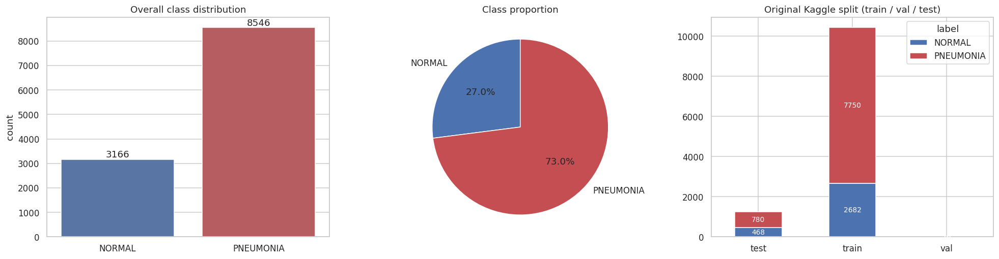

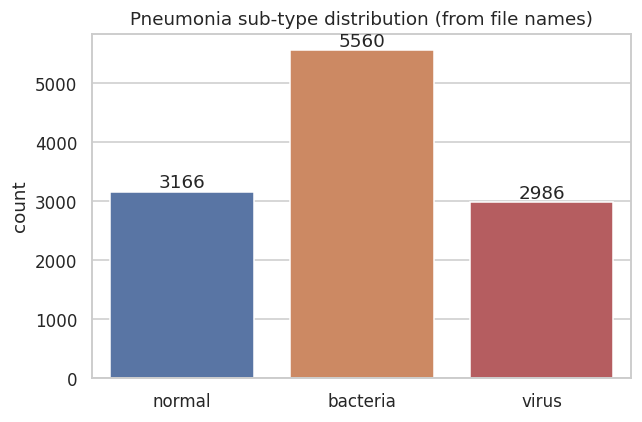

In [ ]:
display(df.groupby(['orig_split', 'label']).size().unstack(fill_value=0).assign(total=lambda t: t.sum(axis=1)))
display(df.subtype.value_counts().to_frame('count'))

counts = df.label.value_counts().reindex(CLASS_NAMES)
print(f'Imbalance ratio (PNEUMONIA : NORMAL) = {counts["PNEUMONIA"] / counts["NORMAL"]:.2f} : 1')

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
sns.countplot(data=df, x='label', order=CLASS_NAMES, hue='label', palette=COLORS, legend=False, ax=ax[0])
for c in ax[0].containers: ax[0].bar_label(c)
ax[0].set_title('Overall class distribution'); ax[0].set_xlabel('')

ax[1].pie(counts.values, labels=CLASS_NAMES, autopct='%1.1f%%', colors=[COLORS[c] for c in CLASS_NAMES],
          startangle=90, wedgeprops=dict(edgecolor='white'))
ax[1].set_title('Class proportion')

ct = df.groupby(['orig_split', 'label']).size().unstack(fill_value=0)[CLASS_NAMES]
ct.plot(kind='bar', stacked=True, ax=ax[2], color=[COLORS[c] for c in CLASS_NAMES], rot=0)
for c in ax[2].containers: ax[2].bar_label(c, label_type='center', color='white', fontsize=9)
ax[2].set_title('Original Kaggle split (train / val / test)'); ax[2].set_xlabel('')
save_show('01_class_distribution')

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='subtype', order=['normal', 'bacteria', 'virus'], hue='subtype', legend=False,
              palette=['#4C72B0', '#DD8452', '#C44E52'], ax=ax)
for c in ax.containers: ax.bar_label(c)
ax.set_title('Pneumonia sub-type distribution (from file names)'); ax.set_xlabel('')
save_show('02_subtype_distribution')

### 2.2 Image visualisation

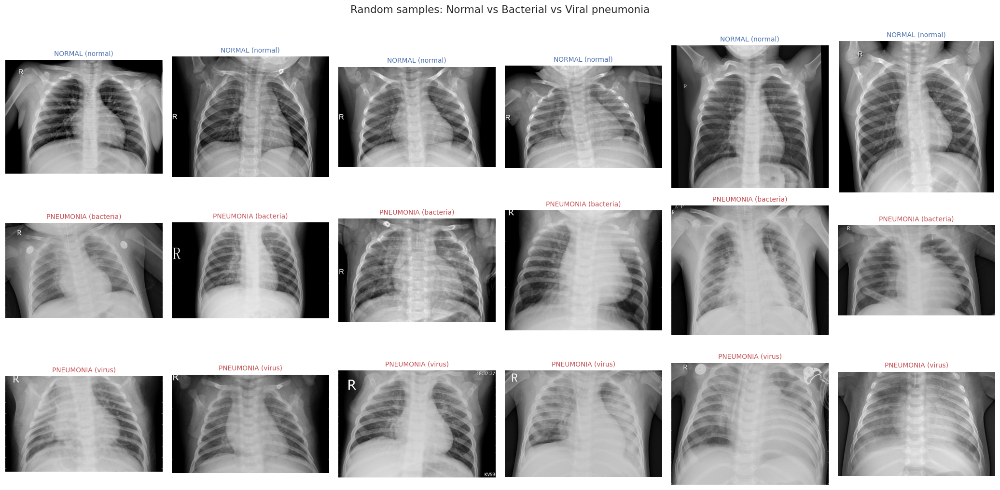

In [ ]:
groups = [('NORMAL', 'normal'), ('PNEUMONIA', 'bacteria'), ('PNEUMONIA', 'virus')]
fig, axes = plt.subplots(3, 6, figsize=(19, 9.5))
for r, (lab, sub) in enumerate(groups):
    sample = df[(df.label == lab) & (df.subtype == sub)].sample(6, random_state=SEED)
    for c, (_, row) in enumerate(sample.iterrows()):
        axes[r, c].imshow(Image.open(row.path).convert('L'), cmap='gray')
        axes[r, c].set_title(f'{lab} ({sub})', fontsize=9, color=COLORS[lab]); axes[r, c].axis('off')
plt.suptitle('Random samples: Normal vs Bacterial vs Viral pneumonia', y=1.0, fontsize=14)
save_show('03_sample_images')

### 2.3 Image statistics

Reading image headers:   0%|          | 0/11712 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
width,11712.0,1327.88,363.49,384.00,1056.00,1281.00,1560.00,2916.00
height,11712.0,970.69,383.38,127.00,688.00,888.00,1187.00,2713.00
aspect,11712.0,1.44,0.25,0.84,1.26,1.42,1.59,3.38
size_kb,11712.0,206.20,258.59,5.31,54.75,93.59,230.48,2357.76


,count
mode,
L,11146
RGB,566


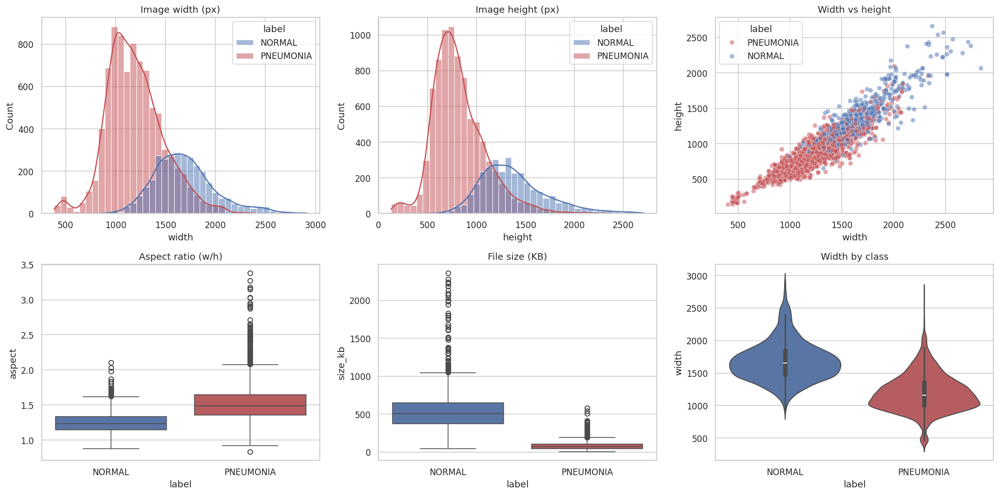

mean_intensity         std_intensity        
                    mean     std          mean     std
label                                                 
NORMAL            0.4795  0.0540        0.2361  0.0203
PNEUMONIA         0.4819  0.0749        0.2168  0.0378

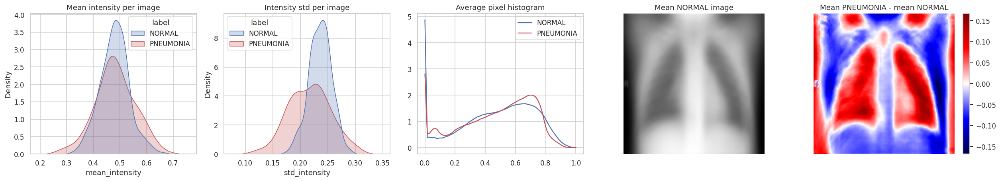

In [ ]:
def read_meta(p):
    try:
        with Image.open(p) as im:
            return im.width, im.height, im.mode
    except Exception:
        return np.nan, np.nan, 'ERR'

with ThreadPoolExecutor(8) as ex:
    meta = list(tqdm(ex.map(read_meta, df.path), total=len(df), desc='Reading image headers'))
df[['width', 'height', 'mode']] = pd.DataFrame(meta)
df['aspect'] = df.width / df.height
df['size_kb'] = df.path.map(lambda p: os.path.getsize(p) / 1024)

display(df[['width', 'height', 'aspect', 'size_kb']].describe().T.round(2))
display(df['mode'].value_counts().to_frame('count'))

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
sns.histplot(data=df, x='width', hue='label', palette=COLORS, bins=40, ax=ax[0, 0], kde=True); ax[0, 0].set_title('Image width (px)')
sns.histplot(data=df, x='height', hue='label', palette=COLORS, bins=40, ax=ax[0, 1], kde=True); ax[0, 1].set_title('Image height (px)')
sns.scatterplot(data=df.sample(min(2000, len(df)), random_state=SEED), x='width', y='height', hue='label',
                palette=COLORS, alpha=0.5, ax=ax[0, 2]); ax[0, 2].set_title('Width vs height')
sns.boxplot(data=df, x='label', y='aspect', hue='label', palette=COLORS, legend=False, ax=ax[1, 0]); ax[1, 0].set_title('Aspect ratio (w/h)')
sns.boxplot(data=df, x='label', y='size_kb', hue='label', palette=COLORS, legend=False, ax=ax[1, 1]); ax[1, 1].set_title('File size (KB)')
sns.violinplot(data=df, x='label', y='width', hue='label', palette=COLORS, legend=False, ax=ax[1, 2]); ax[1, 2].set_title('Width by class')
save_show('04_image_size_statistics')

# Pixel-intensity statistics on a class-balanced sample
samp = df.groupby('label').sample(300, random_state=SEED)
def gray128(p):
    return np.asarray(Image.open(p).convert('L').resize((128, 128)), dtype=np.float32) / 255.0
arrs = {lab: np.stack([gray128(p) for p in samp[samp.label == lab].path]) for lab in CLASS_NAMES}
pix = pd.DataFrame({'label': np.repeat(CLASS_NAMES, 300),
                    'mean_intensity': np.concatenate([arrs[l].mean((1, 2)) for l in CLASS_NAMES]),
                    'std_intensity': np.concatenate([arrs[l].std((1, 2)) for l in CLASS_NAMES])})
display(pix.groupby('label').agg(['mean', 'std']).round(4))

fig, ax = plt.subplots(1, 5, figsize=(23, 4.3))
sns.kdeplot(data=pix, x='mean_intensity', hue='label', palette=COLORS, fill=True, ax=ax[0]); ax[0].set_title('Mean intensity per image')
sns.kdeplot(data=pix, x='std_intensity', hue='label', palette=COLORS, fill=True, ax=ax[1]); ax[1].set_title('Intensity std per image')
for l in CLASS_NAMES:
    h = np.histogram(arrs[l].ravel(), bins=64, range=(0, 1), density=True)[0]
    ax[2].plot(np.linspace(0, 1, 64), h, label=l, color=COLORS[l])
ax[2].legend(); ax[2].set_title('Average pixel histogram')
ax[3].imshow(arrs['NORMAL'].mean(0), cmap='gray'); ax[3].set_title('Mean NORMAL image'); ax[3].axis('off')
d = arrs['PNEUMONIA'].mean(0) - arrs['NORMAL'].mean(0)
im = ax[4].imshow(d, cmap='seismic', vmin=-np.abs(d).max(), vmax=np.abs(d).max()); ax[4].axis('off')
ax[4].set_title('Mean PNEUMONIA - mean NORMAL'); plt.colorbar(im, ax=ax[4], fraction=0.046)
save_show('05_pixel_statistics')

## 3. Data cleaning
Corrupted-file removal, validation, exact-duplicate removal (MD5), near-duplicate grouping (difference hash), and a **patient-level leakage audit**.
The Kermany dataset has no patient metadata column, but patient IDs are encoded in file names (`personXX_bacteria_YY.jpeg`, `IM-XXXX-YYYY.jpeg`).

Integrity / hashing:   0%|          | 0/11712 [00:00<?, ?it/s]

Images before cleaning : 11712
Removed                : 5888


,count
reason,
exact duplicate,5888


Exact-duplicate groups spanning original train/val/test: 0
Images after cleaning  : 5824
Corrupted files check  : 0 found
Near-duplicate hash groups (>1 image): 185 covering 442 images


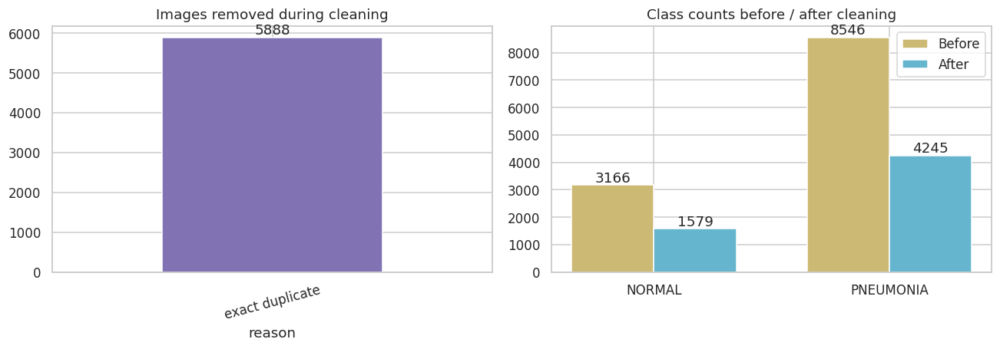

In [ ]:
def analyze(p):
    """MD5 of file bytes, integrity check, difference-hash and pixel std for validation."""
    try:
        with open(p, 'rb') as f:
            md5 = hashlib.md5(f.read()).hexdigest()
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            im.load()
            g = im.convert('L')
            small = np.asarray(g.resize((9, 8), Image.LANCZOS), dtype=np.float32)
            dhash = ''.join('1' if v else '0' for v in (small[:, 1:] > small[:, :-1]).ravel())
            std = float(np.asarray(g.resize((64, 64)), dtype=np.float32).std())
        return dict(md5=md5, dhash=dhash, pix_std=std, ok=True)
    except Exception as e:
        return dict(md5=None, dhash=None, pix_std=np.nan, ok=False)

with ThreadPoolExecutor(8) as ex:
    res = list(tqdm(ex.map(analyze, df.path), total=len(df), desc='Integrity / hashing'))
df = pd.concat([df.reset_index(drop=True), pd.DataFrame(res)], axis=1)

n_before = df.label.value_counts().reindex(CLASS_NAMES)

# exact duplicates that straddle the ORIGINAL splits (leakage in the Kaggle layout itself)
cross = df[df.ok].groupby('md5').orig_split.nunique()
n_cross_dups = int((cross > 1).sum())

df['reason'] = ''
df.loc[~df.ok, 'reason'] = 'corrupted'
df.loc[df.ok & ((df.width < 64) | (df.height < 64) | (df.pix_std < 1.0)), 'reason'] = 'invalid (tiny / blank)'

valid = df[df.reason == '']
conf = valid.groupby('md5').label.nunique()
df.loc[df.md5.isin(conf[conf > 1].index) & (df.reason == ''), 'reason'] = 'duplicate with label conflict'

valid = df[df.reason == '']
dup = valid.duplicated('md5', keep='first')
df.loc[valid.index[dup], 'reason'] = 'exact duplicate'

removed = df[df.reason != '']
df_clean = df[df.reason == ''].copy().reset_index(drop=True)

print(f'Images before cleaning : {len(df)}')
print(f'Removed                : {len(removed)}')
display(removed.reason.value_counts().to_frame('count'))
print(f'Exact-duplicate groups spanning original train/val/test: {n_cross_dups}')
print(f'Images after cleaning  : {len(df_clean)}')
print(f'Corrupted files check  : {(~df.ok).sum()} found')

# Near-duplicates (identical 64-bit difference hash) - reported and later forced into the same split
nd = df_clean.groupby('dhash').size()
print(f'Near-duplicate hash groups (>1 image): {(nd > 1).sum()} covering {nd[nd > 1].sum()} images')

n_after = df_clean.label.value_counts().reindex(CLASS_NAMES)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
if len(removed):
    removed.reason.value_counts().plot(kind='bar', ax=ax[0], color='#8172B3', rot=15)
    for c in ax[0].containers: ax[0].bar_label(c)
ax[0].set_title('Images removed during cleaning')
x = np.arange(2); w = 0.35
ax[1].bar(x - w / 2, n_before.values, w, label='Before', color='#CCB974')
ax[1].bar(x + w / 2, n_after.values, w, label='After', color='#64B5CD')
ax[1].set_xticks(x); ax[1].set_xticklabels(CLASS_NAMES); ax[1].legend(); ax[1].set_title('Class counts before / after cleaning')
for c in ax[1].containers: ax[1].bar_label(c)
save_show('06_cleaning_summary')

# Data validation report
valid_report = dict(total_before=int(len(df)), corrupted=int((~df.ok).sum()), removed_total=int(len(removed)),
                    removed_by_reason=removed.reason.value_counts().to_dict(), total_after=int(len(df_clean)),
                    cross_split_exact_duplicate_groups=n_cross_dups,
                    near_duplicate_groups=int((nd > 1).sum()),
                    min_width=int(df_clean.width.min()), min_height=int(df_clean.height.min()),
                    class_counts_after=n_after.to_dict())
json.dump(valid_report, open(DIRS['results'] / 'data_validation_report.json', 'w'), indent=2)

### 3.1 Patient-level leakage audit

Unique patient IDs : 2789 | images: 5824
Images per patient : {'count': 2789.0, 'mean': 2.09, 'std': 1.8, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 2.0, 'max': 31.0}
Leakage-safe groups (patients merged by near-duplicates): 2532


,train & val,train & test,val & test
patients shared,0,264,0


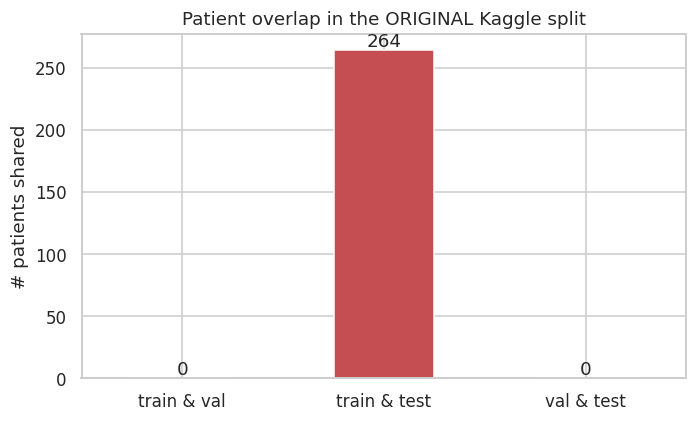

-> We therefore ignore the original split and re-split by patient group below.


In [ ]:
def patient_id(fname, label):
    m = re.match(r'person(\d+)_', fname, re.I)           # personXX_bacteria_YY.jpeg / personXX_virus_YY.jpeg
    if m: return f'{label}_P{m.group(1)}'
    m = re.search(r'IM-(\d+)', fname, re.I)              # IM-XXXX-YYYY.jpeg / NORMAL2-IM-XXXX-YYYY.jpeg
    if m: return f'{label}_N{m.group(1)}'
    return f'{label}_{fname}'                            # unknown pattern -> treat as its own patient

df_clean['pid'] = [patient_id(f, l) for f, l in zip(df_clean.fname, df_clean.label)]
print('Unique patient IDs :', df_clean.pid.nunique(), '| images:', len(df_clean))
print('Images per patient :', df_clean.groupby('pid').size().describe().round(2).to_dict())

# Union-find: merge patients linked by near-duplicate images so they can never be split apart
parent = {p: p for p in df_clean.pid.unique()}
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb: parent[rb] = ra
for _, g in df_clean.groupby('dhash'):
    ids = g.pid.unique()
    for other in ids[1:]:
        union(ids[0], other)
df_clean['group'] = df_clean.pid.map(find)
print('Leakage-safe groups (patients merged by near-duplicates):', df_clean.group.nunique())

# Audit of the ORIGINAL Kaggle train/val/test split
sets = {s: set(df_clean[df_clean.orig_split == s].pid) for s in ['train', 'val', 'test']}
audit = pd.DataFrame({'train & val': [len(sets['train'] & sets['val'])],
                      'train & test': [len(sets['train'] & sets['test'])],
                      'val & test': [len(sets['val'] & sets['test'])]}, index=['patients shared'])
display(audit)
fig, ax = plt.subplots(figsize=(6.5, 4))
audit.T.plot(kind='bar', legend=False, ax=ax, color='#C44E52', rot=0)
for c in ax.containers: ax.bar_label(c)
ax.set_title('Patient overlap in the ORIGINAL Kaggle split'); ax.set_ylabel('# patients shared')
save_show('07_original_split_leakage_audit')
print('-> We therefore ignore the original split and re-split by patient group below.')

## 4. Data splitting - 70% train / 15% validation / 15% test (stratified, patient-level)

Leakage check passed: zero shared patients / files between train, val and test.



label,NORMAL,PNEUMONIA,total,% of data,% pneumonia
split,,,,,
train,1128,2878,4006,68.8,71.8
val,218,696,914,15.7,76.1
test,233,671,904,15.5,74.2


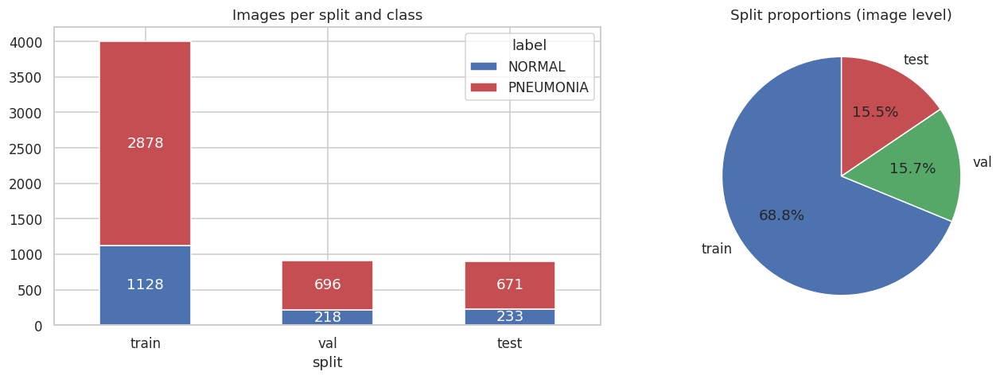

In [ ]:
pat = (df_clean.groupby('group')
       .agg(label_id=('label_id', lambda s: int(round(s.mean()))), n_images=('path', 'size'))
       .reset_index())

tr_p, tmp_p = train_test_split(pat, test_size=0.30, stratify=pat.label_id, random_state=SEED)
va_p, te_p = train_test_split(tmp_p, test_size=0.50, stratify=tmp_p.label_id, random_state=SEED)

split_map = {g: 'train' for g in tr_p.group}
split_map.update({g: 'val' for g in va_p.group})
split_map.update({g: 'test' for g in te_p.group})
df_clean['split'] = df_clean.group.map(split_map)

train_df = df_clean[df_clean.split == 'train'].reset_index(drop=True)
val_df = df_clean[df_clean.split == 'val'].reset_index(drop=True)
test_df = df_clean[df_clean.split == 'test'].reset_index(drop=True)

# --- Leakage verification: no patient-group and no file hash may appear in two splits
G = {n: set(d.group) for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]}
H = {n: set(d.md5) for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]}
assert not (G['train'] & G['val']) and not (G['train'] & G['test']) and not (G['val'] & G['test']), 'Patient leakage!'
assert not (H['train'] & H['val']) and not (H['train'] & H['test']) and not (H['val'] & H['test']), 'File leakage!'
print('Leakage check passed: zero shared patients / files between train, val and test.\n')

summary = (df_clean.groupby(['split', 'label']).size().unstack(fill_value=0)[CLASS_NAMES]
           .reindex(['train', 'val', 'test']))
summary['total'] = summary.sum(axis=1)
summary['% of data'] = (100 * summary.total / summary.total.sum()).round(1)
summary['% pneumonia'] = (100 * summary.PNEUMONIA / summary.total).round(1)
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
summary[CLASS_NAMES].plot(kind='bar', stacked=True, ax=ax[0], color=[COLORS[c] for c in CLASS_NAMES], rot=0)
for c in ax[0].containers: ax[0].bar_label(c, label_type='center', color='white')
ax[0].set_title('Images per split and class')
ax[1].pie(summary.total, labels=summary.index, autopct='%1.1f%%', startangle=90,
          colors=['#4C72B0', '#55A868', '#C44E52'], wedgeprops=dict(edgecolor='white'))
ax[1].set_title('Split proportions (image level)')
save_show('08_split_distribution')

df_clean.drop(columns=['ok']).to_csv(DIRS['results'] / 'dataset_splits.csv', index=False)
summary.to_csv(DIRS['results'] / 'split_summary.csv')

## 5. Image preprocessing: resize to 224x224, RGB conversion, pixel normalisation to [0, 1]

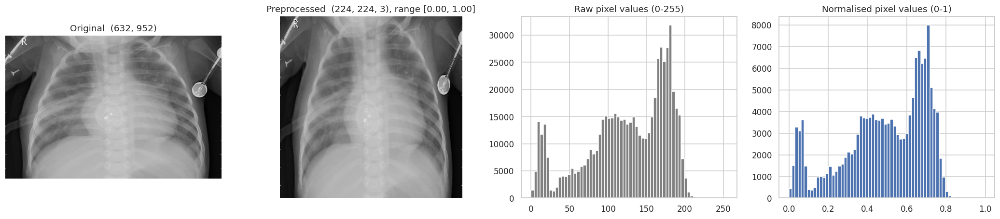

In [ ]:
IMG_SIZE = 224
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_img(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)   # grayscale -> RGB
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))                     # 224 x 224
    img = tf.cast(img, tf.float32) / 255.0                               # pixel normalisation 0-1
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img, tf.cast(label, tf.float32)

# Visual proof of the preprocessing
s = train_df.sample(1, random_state=7).iloc[0]
raw_img = np.asarray(Image.open(s.path))
proc, _ = load_img(s.path, s.label_id)
proc = proc.numpy()
fig, ax = plt.subplots(1, 4, figsize=(19, 4.3))
ax[0].imshow(raw_img, cmap='gray'); ax[0].set_title(f'Original  {raw_img.shape}'); ax[0].axis('off')
ax[1].imshow(proc); ax[1].set_title(f'Preprocessed  {proc.shape}, range [{proc.min():.2f}, {proc.max():.2f}]'); ax[1].axis('off')
ax[2].hist(raw_img.ravel(), bins=64, color='gray'); ax[2].set_title('Raw pixel values (0-255)')
ax[3].hist(proc.ravel(), bins=64, color='#4C72B0'); ax[3].set_title('Normalised pixel values (0-1)')
save_show('09_preprocessing_example')

## 6. Data augmentation (rotation, zoom, translation, contrast) - applied to the training set only

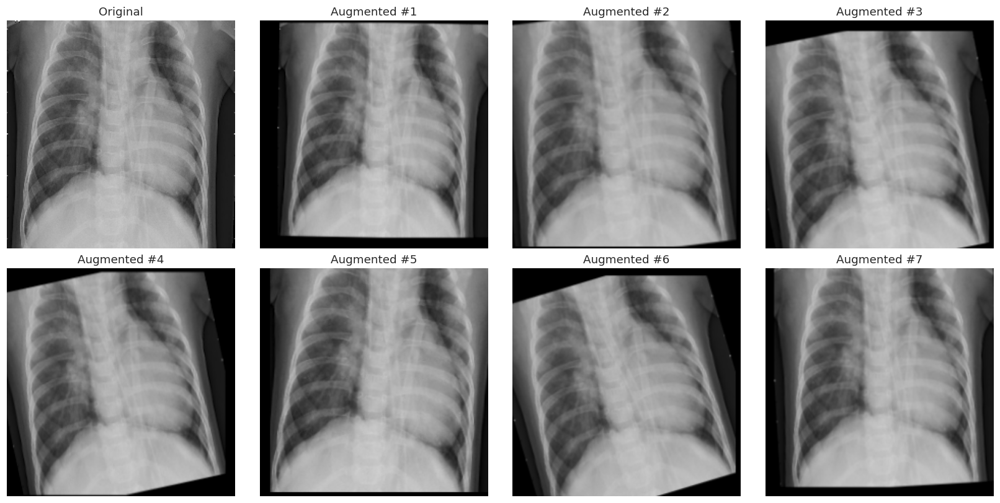

Class weights: {0: np.float64(1.776), 1: np.float64(0.696)}


In [ ]:
augmenter = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.RandomRotation(0.05, fill_mode='constant', fill_value=0.0),               # about +/-18 degrees
    layers.RandomZoom(0.10, fill_mode='constant', fill_value=0.0),                   # +/-10 %
    layers.RandomTranslation(0.05, 0.05, fill_mode='constant', fill_value=0.0),      # +/-5 %
    layers.RandomContrast(0.15),                                                     # contrast jitter
], name='augmentation')

def aug_map(x, y):
    # Keras 3 expects batched inputs when using an Input layer with Sequential
    # We add a batch dimension, augment, and squeeze it back
    x = augmenter(tf.expand_dims(x, 0), training=True)
    return tf.squeeze(tf.clip_by_value(x, 0.0, 1.0), axis=0), y

def make_ds(d, training=False):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label_id.values.astype('float32')))
    if training:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_img, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(aug_map, num_parallel_calls=AUTOTUNE)          # augmentation: training data only
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)
train_eval_ds = make_ds(train_df)       # un-augmented copy used only for evaluation

# Augmentation preview
s = train_df.sample(1, random_state=3).iloc[0]
base, _ = load_img(s.path, s.label_id)
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
axes[0, 0].imshow(base); axes[0, 0].set_title('Original')
for i, a in enumerate(axes.ravel()[1:], 1):
    a.imshow(np.clip(augmenter(base[None], training=True)[0].numpy(), 0, 1)); a.set_title(f'Augmented #{i}')
for a in axes.ravel(): a.axis('off')
save_show('10_augmentation_examples')

# Class weights (training set only) to handle the imbalance
n0, n1 = (train_df.label_id == 0).sum(), (train_df.label_id == 1).sum()
CLASS_WEIGHT = {0: len(train_df) / (2 * n0), 1: len(train_df) / (2 * n1)}
print('Class weights:', {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

## 7. Deep learning model development: Custom CNN and DenseNet121

In [ ]:
def build_custom_cnn():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name='xray')
    x = inp
    for f in [32, 64, 128, 256]:                                  # convolution + max pooling feature extraction
        x = layers.Conv2D(f, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
        x = layers.Conv2D(f, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(0.2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)                   # dense layers
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(64, activation='relu')(x)
    out = layers.Dense(1, activation='sigmoid', name='pneumonia_prob')(x)
    return keras.Model(inp, out, name='custom_cnn')

def build_densenet121():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name='xray')
    # inputs are in [0,1]; apply ImageNet mean/std exactly as DenseNet's pretrained weights expect
    x = layers.Normalization(mean=[0.485, 0.456, 0.406], variance=[0.229 ** 2, 0.224 ** 2, 0.225 ** 2],
                             name='imagenet_norm')(inp)
    base = keras.applications.DenseNet121(include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False                                        # stage 1: frozen pretrained feature extractor
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid', name='pneumonia_prob')(x)
    return keras.Model(inp, out, name='densenet121_tl'), base

custom_cnn = build_custom_cnn()
densenet, dn_base = build_densenet121()
custom_cnn.summary()
print('\nCustom CNN params   :', f'{custom_cnn.count_params():,}')
print('DenseNet121 params  :', f'{densenet.count_params():,}')

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray (InputLayer)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,257,441 (4.80 MB)

 Trainable params: 1,255,521 (4.79 MB)

 Non-trainable params: 1,920 (7.50 KB)


Custom CNN params   : 1,257,441
DenseNet121 params  : 7,172,929


## 8. Model training: Adam, binary cross-entropy, EarlyStopping, ReduceLROnPlateau

In [ ]:
def compile_model(m, lr):
    m.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy',
              metrics=['accuracy', keras.metrics.AUC(name='auc'),
                       keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')])

def make_callbacks(tag):
    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7, verbose=1),
            keras.callbacks.ModelCheckpoint(str(DIRS['weights'] / f'{tag}_best.weights.h5'), monitor='val_loss',
                                            save_best_only=True, save_weights_only=True)]

def merge_hist(*hs):
    out = {}
    for h in hs:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

histories, train_time = {}, {}

# ---- Custom CNN
t0 = time.time()
compile_model(custom_cnn, 1e-3)
h = custom_cnn.fit(train_ds, validation_data=val_ds, epochs=30, class_weight=CLASS_WEIGHT,
                   callbacks=make_callbacks('custom_cnn'), verbose=1)
histories['Custom CNN'] = merge_hist(h)
train_time['Custom CNN'] = time.time() - t0

Epoch 1/30
126/126 ━━━━━━━━━━━━━━━━━━━━ 73s 313ms/step - accuracy: 0.8323 - auc: 0.9092 - loss: 0.3794 - precision: 0.9419 - recall: 0.8169 - val_accuracy: 0.7615 - val_auc: 0.4978 - val_loss: 3.7845 - val_precision: 0.7615 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/30
126/126 ━━━━━━━━━━━━━━━━━━━━ 12s 98ms/step - accuracy: 0.8744 - auc: 0.9399 - loss: 0.3111 - precision: 0.9555 - recall: 0.8655 - val_accuracy: 0.7615 - val_auc: 0.4935 - val_loss: 3.0471 - val_precision: 0.7615 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/30
126/126 ━━━━━━━━━━━━━━━━━━━━ 12s 97ms/step - accuracy: 0.8902 - auc: 0.9556 - loss: 0.2666 - precision: 0.9600 - recall: 0.8839 - val_accuracy: 0.8786 - val_auc: 0.9265 - val_loss: 0.2998 - val_precision: 0.9161 - val_recall: 0.9253 - learning_rate: 0.0010
Epoch 4/30
126/126 ━━━━━━━━━━━━━━━━━━━━ 12s 96ms/step - accuracy: 0.8987 - auc: 0.9618 - loss: 0.2457 - precision: 0.9696 - recall: 0.8867 - val_accuracy: 0.7626 - val_auc: 0.6985 - val_loss: 1.4

In [ ]:
# ---- DenseNet121 stage 1: train the new head on frozen pretrained features
t0 = time.time()
compile_model(densenet, 1e-3)
h1 = densenet.fit(train_ds, validation_data=val_ds, epochs=8, class_weight=CLASS_WEIGHT,
                  callbacks=make_callbacks('densenet121_stage1'), verbose=1)

# ---- DenseNet121 stage 2: fine-tune the last layers with a small learning rate (BatchNorm kept frozen)
dn_base.trainable = True
for l in dn_base.layers[:-60]:
    l.trainable = False
for l in dn_base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
print('Trainable layers in DenseNet backbone:', sum(l.trainable for l in dn_base.layers), '/', len(dn_base.layers))
compile_model(densenet, 1e-5)
h2 = densenet.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=CLASS_WEIGHT,
                  callbacks=make_callbacks('densenet121_finetune'), verbose=1)
histories['DenseNet121'] = merge_hist(h1, h2)
STAGE1_EPOCHS = len(h1.history['loss'])
train_time['DenseNet121'] = time.time() - t0
print({k: f'{v / 60:.1f} min' for k, v in train_time.items()})

Epoch 1/8
126/126 ━━━━━━━━━━━━━━━━━━━━ 107s 543ms/step - accuracy: 0.8729 - auc: 0.9529 - loss: 0.2843 - precision: 0.9561 - recall: 0.8628 - val_accuracy: 0.9212 - val_auc: 0.9793 - val_loss: 0.2080 - val_precision: 0.9845 - val_recall: 0.9109 - learning_rate: 0.0010
Epoch 2/8
126/126 ━━━━━━━━━━━━━━━━━━━━ 13s 100ms/step - accuracy: 0.9191 - auc: 0.9762 - loss: 0.1963 - precision: 0.9726 - recall: 0.9131 - val_accuracy: 0.9376 - val_auc: 0.9795 - val_loss: 0.1557 - val_precision: 0.9637 - val_recall: 0.9540 - learning_rate: 0.0010
Epoch 3/8
126/126 ━━━━━━━━━━━━━━━━━━━━ 12s 90ms/step - accuracy: 0.9254 - auc: 0.9788 - loss: 0.1853 - precision: 0.9722 - recall: 0.9225 - val_accuracy: 0.9354 - val_auc: 0.9781 - val_loss: 0.1606 - val_precision: 0.9623 - val_recall: 0.9526 - learning_rate: 0.0010
Epoch 4/8
125/126 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9365 - auc: 0.9845 - loss: 0.1566 - precision: 0.9773 - recall: 0.9340
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0003

### 8.1 Training curves

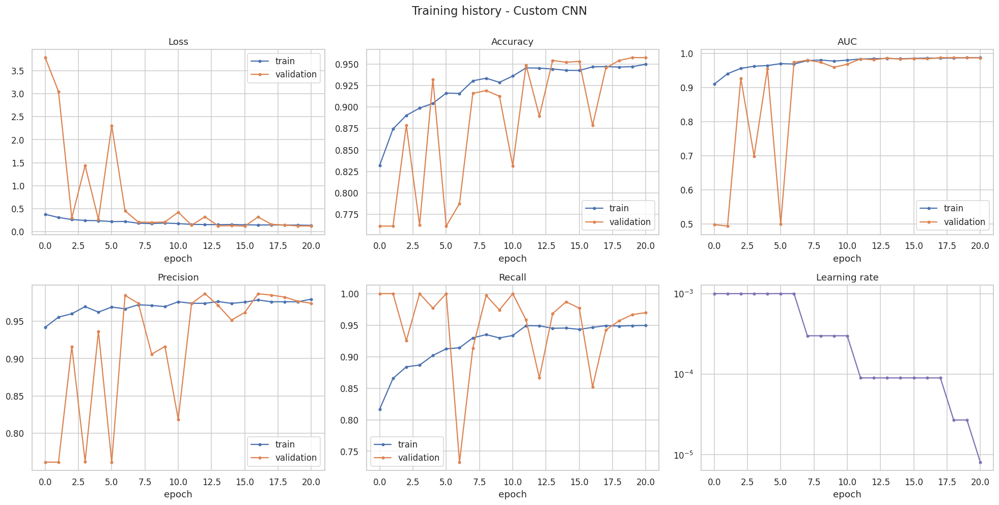

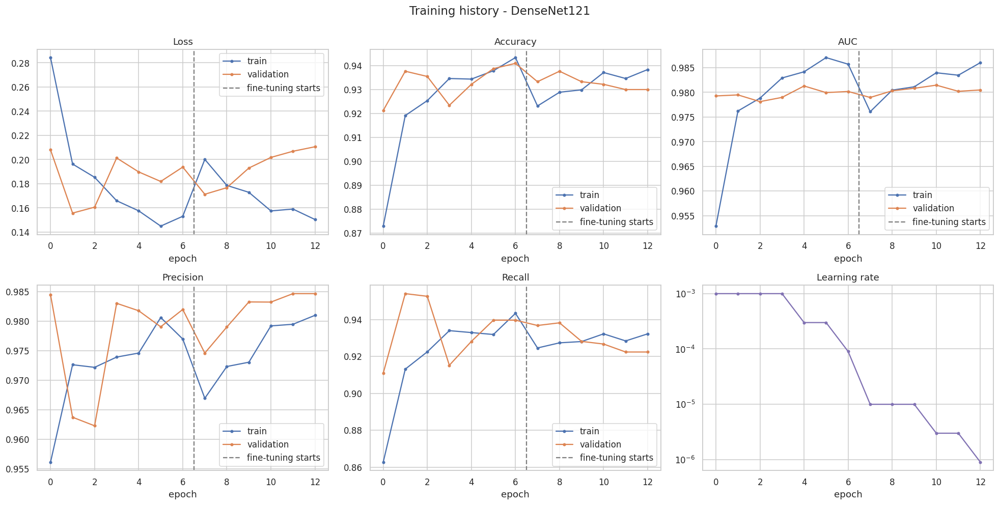

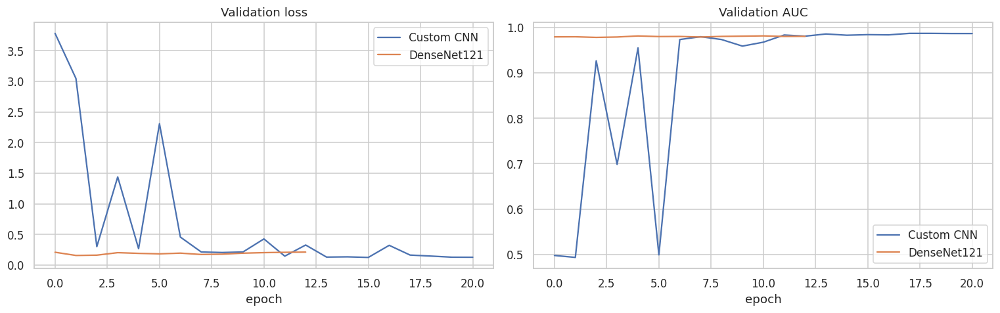

In [ ]:
def plot_history(h, name, split_at=None):
    items = [('loss', 'Loss'), ('accuracy', 'Accuracy'), ('auc', 'AUC'), ('precision', 'Precision'), ('recall', 'Recall')]
    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    axes = axes.ravel()
    for ax, (k, t) in zip(axes, items):
        ax.plot(h[k], label='train', marker='o', ms=3); ax.plot(h['val_' + k], label='validation', marker='o', ms=3)
        if split_at: ax.axvline(split_at - 0.5, ls='--', c='gray', label='fine-tuning starts')
        ax.set_title(t); ax.set_xlabel('epoch'); ax.legend()
    lr_key = next((k for k in ['learning_rate', 'lr'] if k in h), None)
    if lr_key:
        axes[5].semilogy(h[lr_key], marker='o', ms=3, color='#8172B3'); axes[5].set_title('Learning rate'); axes[5].set_xlabel('epoch')
    else:
        axes[5].axis('off')
    plt.suptitle(f'Training history - {name}', fontsize=15, y=1.0)
    save_show(f'11_training_curves_{name.lower().replace(" ", "_")}')

plot_history(histories['Custom CNN'], 'Custom CNN')
plot_history(histories['DenseNet121'], 'DenseNet121', split_at=STAGE1_EPOCHS)

json.dump({n: {k: [float(x) for x in v] for k, v in h.items()} for n, h in histories.items()}, open(DIRS['results'] / 'training_histories.json', 'w'))

# Side-by-side validation comparison
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for n, h in histories.items():
    ax[0].plot(h['val_loss'], label=n); ax[1].plot(h['val_auc'], label=n)
ax[0].set_title('Validation loss'); ax[1].set_title('Validation AUC')
for a in ax: a.set_xlabel('epoch'); a.legend()
save_show('12_validation_comparison')

### 8.2 Save trained models and weights

In [ ]:
MODELS = {'Custom CNN': custom_cnn, 'DenseNet121': densenet}
for n, m in MODELS.items():
    tag = n.lower().replace(' ', '_')
    m.save(DIRS['models'] / f'{tag}_final.keras')
    m.save_weights(DIRS['weights'] / f'{tag}_final.weights.h5')
print(sorted(p.name for p in list(DIRS['models'].glob('*')) + list(DIRS['weights'].glob('*'))))

['custom_cnn_best.weights.h5', 'custom_cnn_final.keras', 'custom_cnn_final.weights.h5', 'densenet121_final.keras', 'densenet121_final.weights.h5', 'densenet121_finetune_best.weights.h5', 'densenet121_stage1_best.weights.h5']


## 9. Model evaluation: Accuracy, Precision, Recall, Specificity, F1, ROC-AUC, confusion matrix

In [ ]:
def compute_metrics(y, p, thr=0.5):
    yp = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yp, labels=[0, 1]).ravel()
    return dict(Accuracy=accuracy_score(y, yp), Precision=precision_score(y, yp, zero_division=0),
                Recall=recall_score(y, yp), Specificity=tn / (tn + fp), F1=f1_score(y, yp),
                ROC_AUC=roc_auc_score(y, p), PR_AUC=average_precision_score(y, p), Brier=brier_score_loss(y, p),
                TP=int(tp), TN=int(tn), FP=int(fp), FN=int(fn))

DATASETS = {'train': (train_eval_ds, train_df), 'val': (val_ds, val_df), 'test': (test_ds, test_df)}
PROBS, METRICS = {}, {}
for n, m in MODELS.items():
    for s, (ds, d) in DATASETS.items():
        p = m.predict(ds, verbose=0).ravel()
        PROBS[(n, s)] = p
        METRICS[(n, s)] = compute_metrics(d.label_id.values, p)

metrics_df = pd.DataFrame(METRICS).T
metrics_df.index.names = ['Model', 'Split']
metrics_df.round(4).to_csv(DIRS['results'] / 'metrics_all_splits.csv')
cols = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'ROC_AUC']
display(metrics_df[cols + ['TP', 'TN', 'FP', 'FN']].round(4).style.background_gradient(cmap='Greens', subset=cols))

test_tbl = metrics_df.xs('test', level='Split')[cols + ['PR_AUC']].round(4)
test_tbl.to_csv(DIRS['results'] / 'metrics_test.csv')
print('\nTEST SET RESULTS'); display(test_tbl)

for n in MODELS:
    rep = classification_report(test_df.label_id, (PROBS[(n, 'test')] >= 0.5).astype(int), target_names=CLASS_NAMES, digits=4)
    open(DIRS['results'] / f'classification_report_{n.lower().replace(" ", "_")}_test.txt', 'w').write(rep)
    print(f'--- {n} ---\n{rep}')

# Best model is chosen on the VALIDATION set only (never on test)
best_name = max(MODELS, key=lambda n: (METRICS[(n, 'val')]['ROC_AUC'], METRICS[(n, 'val')]['F1']))
print('Best model (by validation ROC-AUC):', best_name)
MODELS[best_name].save(DIRS['models'] / 'best_model.keras')
MODELS[best_name].save_weights(DIRS['weights'] / 'best_model.weights.h5')


TEST SET RESULTS


,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC,PR_AUC
Model,,,,,,,
Custom CNN,0.9502,0.9672,0.9657,0.9056,0.9664,0.9877,0.9957
DenseNet121,0.9425,0.9844,0.9374,0.9571,0.9603,0.9869,0.9954


--- Custom CNN ---
              precision    recall  f1-score   support

      NORMAL     0.9017    0.9056    0.9036       233
   PNEUMONIA     0.9672    0.9657    0.9664       671

    accuracy                         0.9502       904
   macro avg     0.9344    0.9357    0.9350       904
weighted avg     0.9503    0.9502    0.9503       904

--- DenseNet121 ---
              precision    recall  f1-score   support

      NORMAL     0.8415    0.9571    0.8956       233
   PNEUMONIA     0.9844    0.9374    0.9603       671

    accuracy                         0.9425       904
   macro avg     0.9129    0.9472    0.9279       904
weighted avg     0.9475    0.9425    0.9436       904

Best model (by validation ROC-AUC): Custom CNN


### 9.1 Confusion matrices

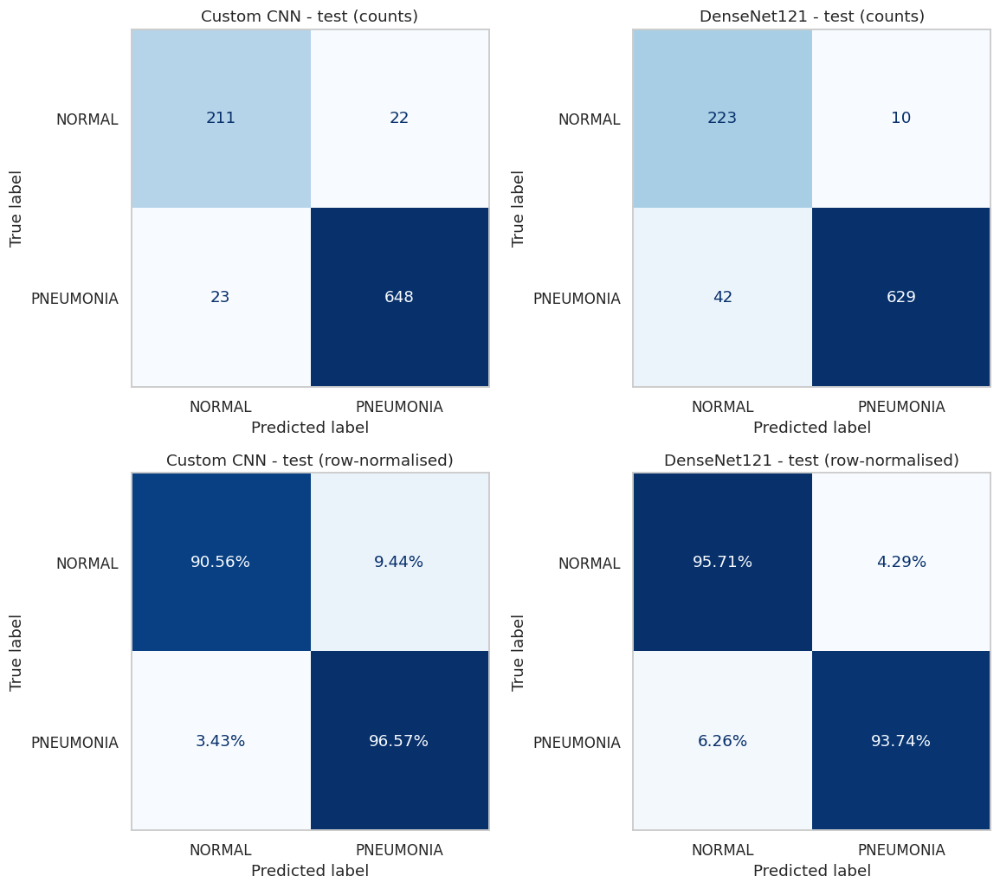

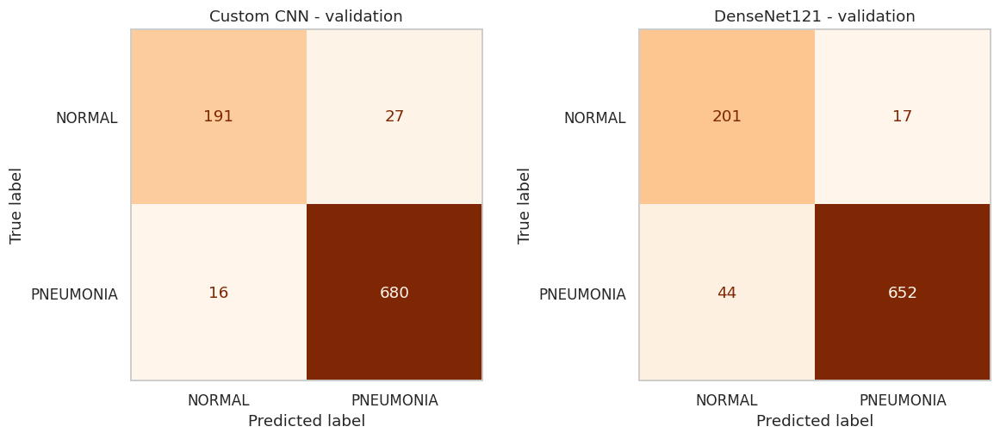

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
for j, n in enumerate(MODELS):
    y = test_df.label_id.values; yp = (PROBS[(n, 'test')] >= 0.5).astype(int)
    ConfusionMatrixDisplay.from_predictions(y, yp, display_labels=CLASS_NAMES, cmap='Blues', ax=axes[0, j], colorbar=False)
    axes[0, j].set_title(f'{n} - test (counts)'); axes[0, j].grid(False)
    ConfusionMatrixDisplay.from_predictions(y, yp, display_labels=CLASS_NAMES, cmap='Blues', normalize='true',
                                            values_format='.2%', ax=axes[1, j], colorbar=False)
    axes[1, j].set_title(f'{n} - test (row-normalised)'); axes[1, j].grid(False)
save_show('13_confusion_matrices_test')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for j, n in enumerate(MODELS):
    ConfusionMatrixDisplay.from_predictions(val_df.label_id.values, (PROBS[(n, 'val')] >= 0.5).astype(int),
                                            display_labels=CLASS_NAMES, cmap='Oranges', ax=axes[j], colorbar=False)
    axes[j].set_title(f'{n} - validation'); axes[j].grid(False)
save_show('14_confusion_matrices_validation')

### 9.2 ROC, precision-recall, calibration and probability distributions

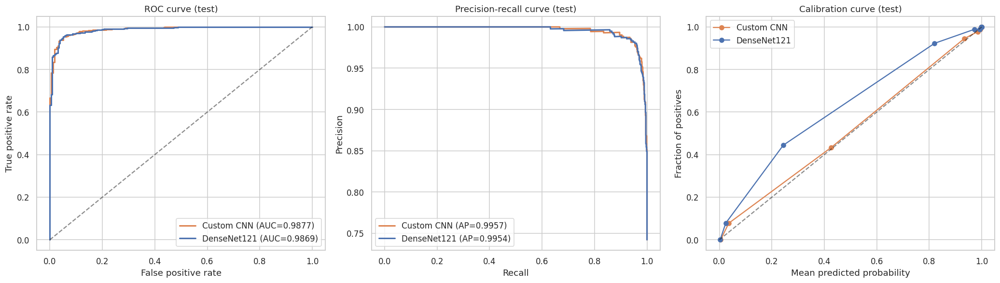

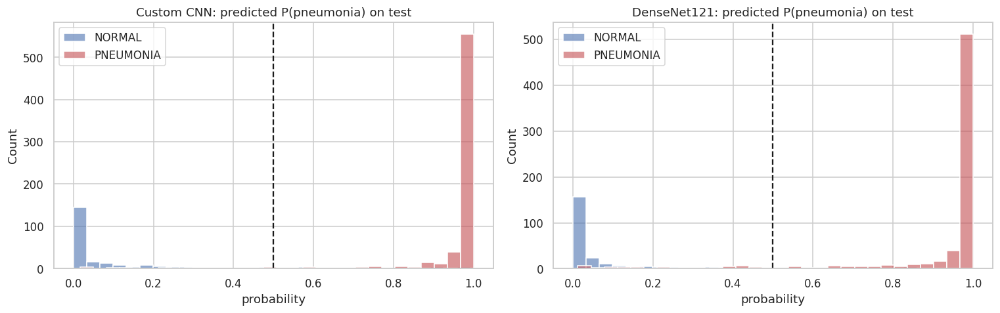

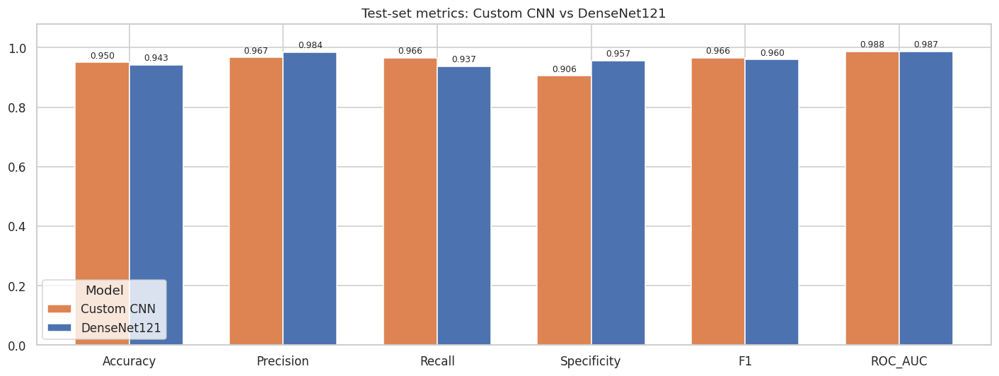

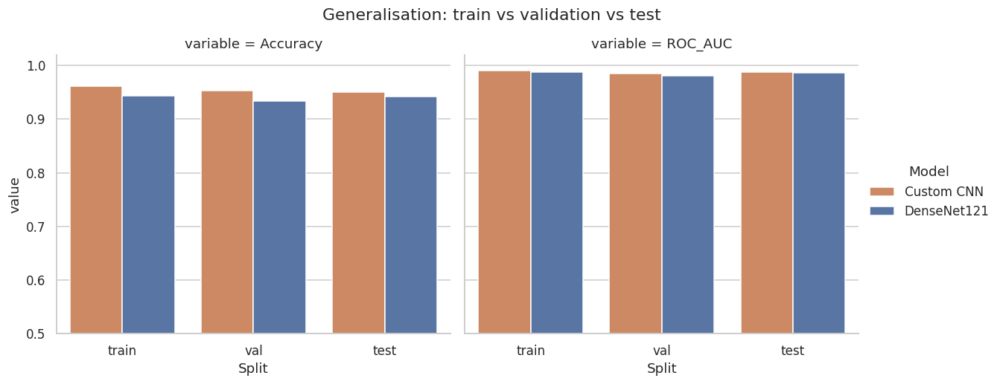

In [ ]:
y_te = test_df.label_id.values
pal = {'Custom CNN': '#DD8452', 'DenseNet121': '#4C72B0'}
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
for n in MODELS:
    p = PROBS[(n, 'test')]
    fpr, tpr, _ = roc_curve(y_te, p); ax[0].plot(fpr, tpr, color=pal[n], lw=2, label=f'{n} (AUC={roc_auc_score(y_te, p):.4f})')
    pr, rc, _ = precision_recall_curve(y_te, p); ax[1].plot(rc, pr, color=pal[n], lw=2, label=f'{n} (AP={average_precision_score(y_te, p):.4f})')
    fp_, mp_ = calibration_curve(y_te, p, n_bins=10, strategy='quantile'); ax[2].plot(mp_, fp_, marker='o', color=pal[n], label=n)
ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.5); ax[0].set_title('ROC curve (test)'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].legend(loc='lower right')
ax[1].set_title('Precision-recall curve (test)'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend(loc='lower left')
ax[2].plot([0, 1], [0, 1], 'k--', alpha=0.5); ax[2].set_title('Calibration curve (test)'); ax[2].set_xlabel('Mean predicted probability'); ax[2].set_ylabel('Fraction of positives'); ax[2].legend()
save_show('15_roc_pr_calibration')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, n in zip(ax, MODELS):
    for lab in [0, 1]:
        sns.histplot(PROBS[(n, 'test')][y_te == lab], bins=30, ax=a, color=COLORS[CLASS_NAMES[lab]], alpha=0.6, label=CLASS_NAMES[lab])
    a.axvline(0.5, ls='--', c='k'); a.set_title(f'{n}: predicted P(pneumonia) on test'); a.set_xlabel('probability'); a.legend()
save_show('16_probability_distributions')

# Metric comparison bar chart
plot_df = test_tbl[cols].T
ax = plot_df.plot(kind='bar', figsize=(13, 5), rot=0, color=[pal[c] for c in plot_df.columns], width=0.7)
for c in ax.containers: ax.bar_label(c, fmt='%.3f', fontsize=8, padding=2)
ax.set_ylim(0, 1.08); ax.set_title('Test-set metrics: Custom CNN vs DenseNet121')
save_show('17_metric_comparison')

# Generalisation gap (train vs val vs test accuracy / AUC)
gap = metrics_df.reset_index().melt(id_vars=['Model', 'Split'], value_vars=['Accuracy', 'ROC_AUC'])
g = sns.catplot(data=gap, x='Split', y='value', hue='Model', col='variable', kind='bar', palette=pal, height=4.5, aspect=1.2, order=['train', 'val', 'test'])
g.set(ylim=(0.5, 1.02)); g.fig.suptitle('Generalisation: train vs validation vs test', y=1.04)
g.fig.savefig(DIRS['plots'] / '18_generalisation_gap.png', bbox_inches='tight'); plt.show()

### 9.3 Threshold analysis and misclassified images

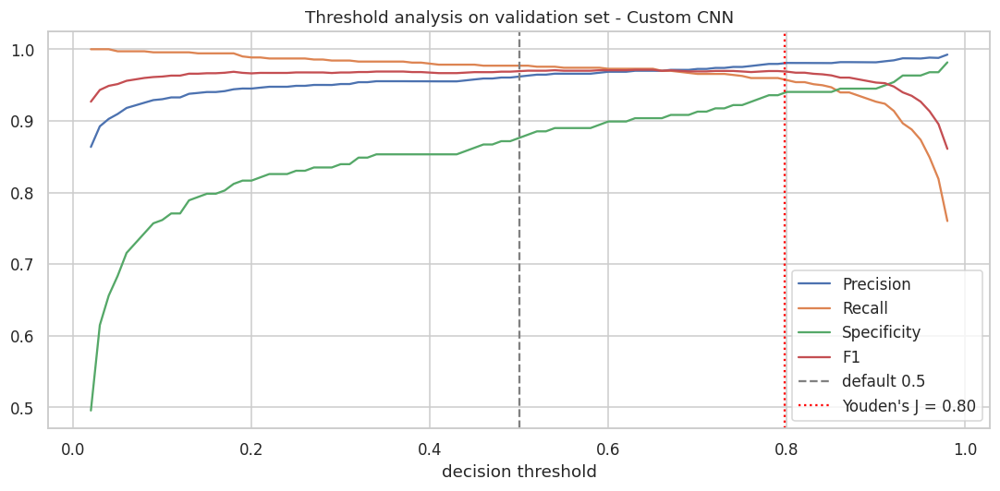

,Accuracy,Precision,Recall,Specificity,F1,ROC_AUC
thr=0.50,0.9502,0.9672,0.9657,0.9056,0.9664,0.9877
thr=0.80 (Youden),0.9447,0.9859,0.9389,0.9614,0.9618,0.9877


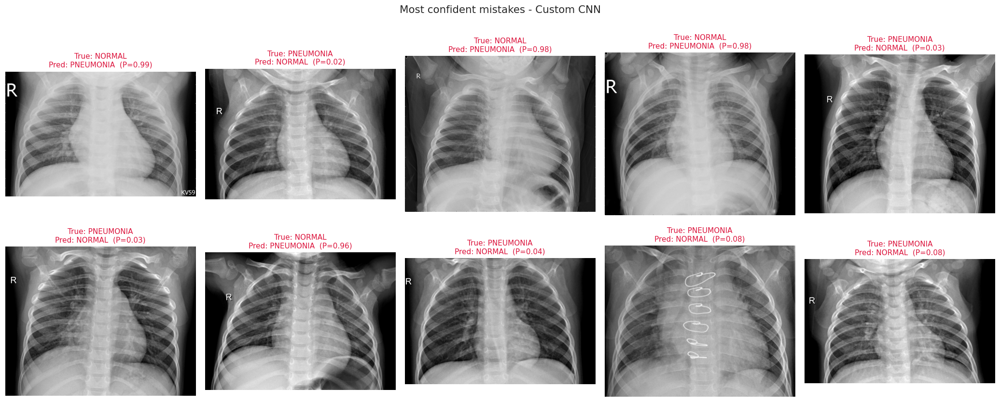

In [ ]:
bm = MODELS[best_name]; pv = PROBS[(best_name, 'val')]; yv = val_df.label_id.values
ths = np.linspace(0.02, 0.98, 97)
curve = pd.DataFrame([dict(thr=t, **{k: v for k, v in compute_metrics(yv, pv, t).items() if k in ['Precision', 'Recall', 'Specificity', 'F1']}) for t in ths])
fpr, tpr, thr_roc = roc_curve(yv, pv)
youden_thr = float(thr_roc[np.argmax(tpr - fpr)])

fig, ax = plt.subplots(figsize=(10, 5))
for k in ['Precision', 'Recall', 'Specificity', 'F1']:
    ax.plot(curve.thr, curve[k], label=k)
ax.axvline(0.5, c='gray', ls='--', label='default 0.5'); ax.axvline(youden_thr, c='red', ls=':', label=f"Youden's J = {youden_thr:.2f}")
ax.set_xlabel('decision threshold'); ax.set_title(f'Threshold analysis on validation set - {best_name}'); ax.legend()
save_show('19_threshold_analysis')

thr_tbl = pd.DataFrame({f'thr=0.50': compute_metrics(y_te, PROBS[(best_name, 'test')], 0.5),
                        f'thr={youden_thr:.2f} (Youden)': compute_metrics(y_te, PROBS[(best_name, 'test')], youden_thr)}).T[cols]
display(thr_tbl.round(4)); thr_tbl.round(4).to_csv(DIRS['results'] / 'threshold_comparison_test.csv')

# Misclassified test images
pt = PROBS[(best_name, 'test')]; pred = (pt >= 0.5).astype(int)
wrong = test_df.assign(prob=pt, pred=pred)[pred != y_te]
wrong = wrong.assign(conf_err=np.abs(wrong.prob - wrong.label_id)).sort_values('conf_err', ascending=False).head(10)
if len(wrong):
    fig, axes = plt.subplots(2, 5, figsize=(19, 8))
    for a, (_, r) in zip(axes.ravel(), wrong.iterrows()):
        a.imshow(Image.open(r.path).convert('L'), cmap='gray')
        a.set_title(f'True: {CLASS_NAMES[r.label_id]}\nPred: {CLASS_NAMES[r.pred]}  (P={r.prob:.2f})', fontsize=10, color='crimson')
    for a in axes.ravel(): a.axis('off')
    plt.suptitle(f'Most confident mistakes - {best_name}', fontsize=14, y=1.0)
    save_show('20_misclassified_examples')

## 10. Explainable AI: LIME and SHAP
Both methods explain the probability of the **PNEUMONIA** class for the best model. Four kinds of test images are explained: true positives, true negatives, false positives, false negatives (when they exist).

Explaining model: Custom CNN
8 samples: Counter({'True Positive': 2, 'True Negative': 2, 'False Positive': 2, 'False Negative': 2})


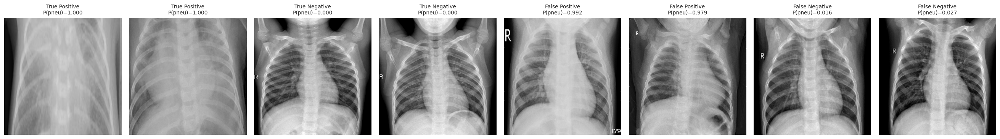

In [ ]:
import shap
from lime import lime_image
from lime.wrappers.scikit_image import SegmentationAlgorithm
from skimage.segmentation import mark_boundaries
from scipy.ndimage import zoom as ndzoom

xai_model = MODELS[best_name]
print('Explaining model:', best_name)

def predict_proba2(x):
    """images in [0,1] -> [P(normal), P(pneumonia)]"""
    p = xai_model.predict(np.asarray(x, dtype=np.float32), batch_size=64, verbose=0).ravel()
    return np.stack([1 - p, p], axis=1)

def load_array(path):
    return load_img(path, 0)[0].numpy()          # exactly the same preprocessing as training

# ---- choose explanation samples from the test set
tdf = test_df.assign(prob=PROBS[(best_name, 'test')])
tdf['pred'] = (tdf.prob >= 0.5).astype(int)
tdf['cat'] = np.select([(tdf.label_id == 1) & (tdf.pred == 1), (tdf.label_id == 0) & (tdf.pred == 0),
                        (tdf.label_id == 0) & (tdf.pred == 1), (tdf.label_id == 1) & (tdf.pred == 0)],
                       ['True Positive', 'True Negative', 'False Positive', 'False Negative'],
                       default='unknown')
XAI_SAMPLES = []
for cat in ['True Positive', 'True Negative', 'False Positive', 'False Negative']:
    sub = tdf[tdf.cat == cat]
    if cat in ('True Positive', 'False Positive'):
        sub = sub.sort_values('prob', ascending=False)
    elif cat == 'True Negative':
        sub = sub.sort_values('prob')
    else:
        sub = sub.sort_values('prob')
    for _, r in sub.head(2).iterrows():
        XAI_SAMPLES.append(dict(path=r.path, y=int(r.label_id), p=float(r.prob), cat=cat, img=load_array(r.path)))
print(f'{len(XAI_SAMPLES)} samples:', Counter(s['cat'] for s in XAI_SAMPLES))

fig, axes = plt.subplots(1, len(XAI_SAMPLES), figsize=(3 * len(XAI_SAMPLES), 3.6))
for a, s in zip(np.atleast_1d(axes), XAI_SAMPLES):
    a.imshow(s['img']); a.set_title(f"{s['cat']}\nP(pneu)={s['p']:.3f}", fontsize=9); a.axis('off')
save_show('21_xai_selected_samples', 'explanations')

### 10.1 LIME - local explanation with superpixel analysis

LIME:   0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

LIME done in 55s


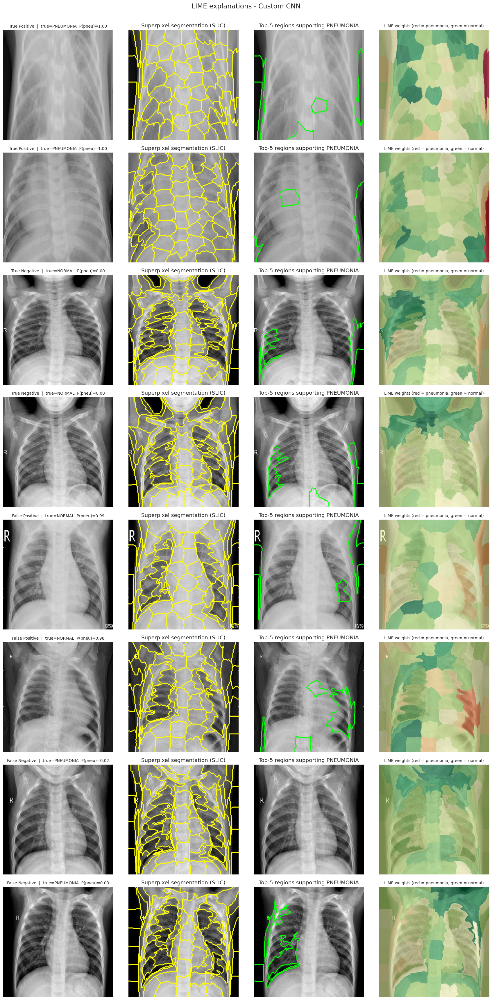

In [ ]:
segfn = SegmentationAlgorithm('slic', n_segments=60, compactness=10, sigma=1, start_label=1)

def run_lime(img, seed=SEED, num_samples=1000):
    explainer = lime_image.LimeImageExplainer(random_state=seed)
    return explainer.explain_instance(img.astype('double'), predict_proba2, labels=(1,), top_labels=None, hide_color=0,
                                      num_samples=num_samples, batch_size=64, segmentation_fn=segfn,
                                      random_seed=seed)

def lime_weight_map(exp, label=1):
    m = np.zeros(exp.segments.shape, np.float32)
    for seg_id, w in exp.local_exp[label]:
        m[exp.segments == seg_id] = w
    return m

t0 = time.time()
for s in tqdm(XAI_SAMPLES, desc='LIME'):
    s['lime_exp'] = run_lime(s['img'])
    s['lime_map'] = lime_weight_map(s['lime_exp'])
print(f'LIME done in {time.time() - t0:.0f}s')

fig, axes = plt.subplots(len(XAI_SAMPLES), 4, figsize=(16, 3.9 * len(XAI_SAMPLES)))
for r, s in enumerate(XAI_SAMPLES):
    exp = s['lime_exp']
    _, mask_pos = exp.get_image_and_mask(1, positive_only=True, num_features=5, hide_rest=False)
    lim = np.abs(s['lime_map']).max() + 1e-8
    axes[r, 0].imshow(s['img']); axes[r, 0].set_title(f"{s['cat']}  |  true={CLASS_NAMES[s['y']]}  P(pneu)={s['p']:.2f}", fontsize=9)
    axes[r, 1].imshow(mark_boundaries(s['img'], exp.segments, color=(1, 1, 0))); axes[r, 1].set_title('Superpixel segmentation (SLIC)')
    axes[r, 2].imshow(mark_boundaries(s['img'], mask_pos, color=(0, 1, 0), mode='thick')); axes[r, 2].set_title('Top-5 regions supporting PNEUMONIA')
    axes[r, 3].imshow(s['img']); im = axes[r, 3].imshow(s['lime_map'], cmap='RdYlGn_r', vmin=-lim, vmax=lim, alpha=0.6)
    axes[r, 3].set_title('LIME weights (red = pneumonia, green = normal)', fontsize=9)
    for a in axes[r]: a.axis('off')
plt.suptitle(f'LIME explanations - {best_name}', fontsize=15, y=1.002)
save_show('22_lime_explanations', 'explanations')

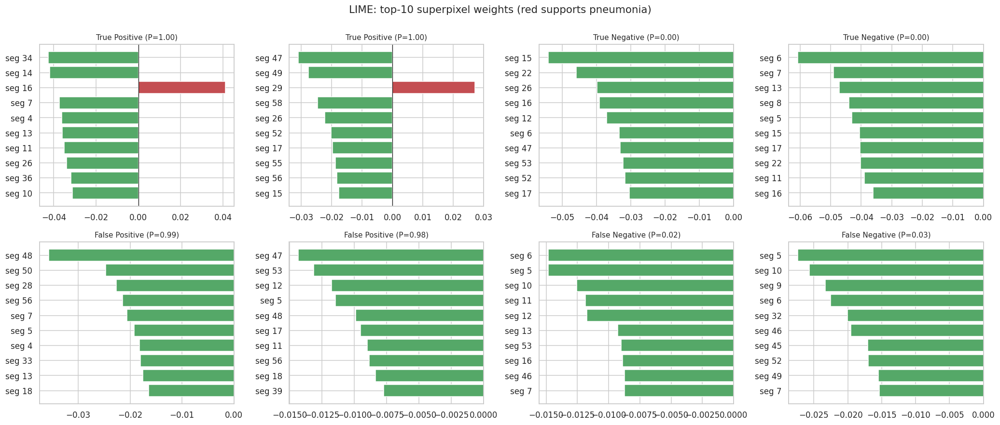

In [32]:
# Superpixel importance for each explained image (top 10 superpixels by |weight|)
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for a, s in zip(axes.ravel(), XAI_SAMPLES):
    w = sorted(s['lime_exp'].local_exp[1], key=lambda t: abs(t[1]), reverse=True)[:10]
    a.barh([f'seg {i}' for i, _ in w][::-1], [v for _, v in w][::-1], color=['#C44E52' if v > 0 else '#55A868' for _, v in w][::-1])
    a.set_title(f"{s['cat']} (P={s['p']:.2f})", fontsize=10); a.axvline(0, c='k', lw=0.8)
for a in axes.ravel()[len(XAI_SAMPLES):]: a.axis('off')
plt.suptitle('LIME: top-10 superpixel weights (red supports pneumonia)', fontsize=14, y=1.0)
save_show('23_lime_superpixel_weights', 'explanations')

### 10.2 SHAP - pixel-level feature attribution heatmaps

SHAP:   0%|          | 0/8 [00:00<?, ?it/s]

SHAP done in 20s


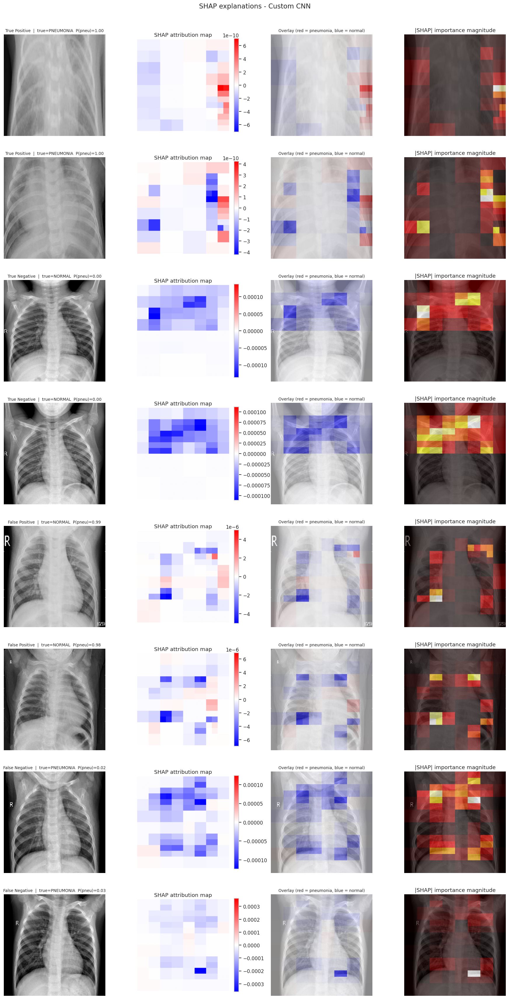

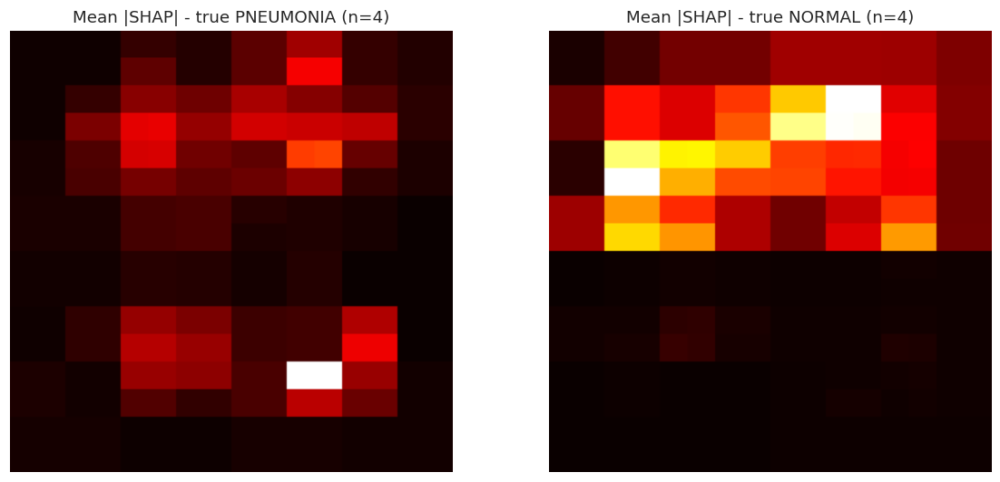

In [33]:
# Model-agnostic Partition SHAP with an image masker. SHAP's image masker expects 0-255 inputs, so we scale
# in and out. 'blur(64,64)' masks regions by blurring them (fast and robust for chest X-rays).
shap_masker = shap.maskers.Image('blur(64,64)', (IMG_SIZE, IMG_SIZE, 3))
shap_f = lambda x: predict_proba2(np.asarray(x) / 255.0)
shap_explainer = shap.Explainer(shap_f, shap_masker, output_names=CLASS_NAMES)

def run_shap(img, max_evals=500):
    sv = shap_explainer((img * 255.0)[None].astype(np.float32), max_evals=max_evals, batch_size=50)
    v = np.asarray(sv.values)[0]                     # (H, W, C, outputs)
    if v.ndim == 4:
        v = v[..., -1]                               # attribution towards PNEUMONIA
    return v.sum(-1).astype(np.float32)              # sum over RGB channels -> (H, W)

t0 = time.time()
for s in tqdm(XAI_SAMPLES, desc='SHAP'):
    s['shap_map'] = run_shap(s['img'])
print(f'SHAP done in {time.time() - t0:.0f}s')

fig, axes = plt.subplots(len(XAI_SAMPLES), 4, figsize=(16, 3.9 * len(XAI_SAMPLES)))
for r, s in enumerate(XAI_SAMPLES):
    m = s['shap_map']; lim = np.abs(m).max() + 1e-12
    axes[r, 0].imshow(s['img']); axes[r, 0].set_title(f"{s['cat']}  |  true={CLASS_NAMES[s['y']]}  P(pneu)={s['p']:.2f}", fontsize=9)
    im = axes[r, 1].imshow(m, cmap='bwr', vmin=-lim, vmax=lim); axes[r, 1].set_title('SHAP attribution map'); plt.colorbar(im, ax=axes[r, 1], fraction=0.046)
    axes[r, 2].imshow(s['img']); axes[r, 2].imshow(m, cmap='bwr', vmin=-lim, vmax=lim, alpha=0.55); axes[r, 2].set_title('Overlay (red = pneumonia, blue = normal)', fontsize=9)
    axes[r, 3].imshow(s['img']); axes[r, 3].imshow(np.abs(m), cmap='hot', alpha=0.6); axes[r, 3].set_title('|SHAP| importance magnitude')
    for a in axes[r]: a.axis('off')
plt.suptitle(f'SHAP explanations - {best_name}', fontsize=15, y=1.002)
save_show('24_shap_explanations', 'explanations')

# Class-wise average attribution (contribution analysis)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for a, c in zip(axes, [1, 0]):
    ms = [np.abs(s['shap_map']) for s in XAI_SAMPLES if s['y'] == c]
    if ms:
        a.imshow(np.mean(ms, 0), cmap='hot'); a.set_title(f'Mean |SHAP| - true {CLASS_NAMES[c]} (n={len(ms)})')
    a.axis('off')
save_show('25_shap_mean_attribution_by_class', 'explanations')

## 11. Explanation comparison: LIME vs SHAP (important regions, agreement, stability)

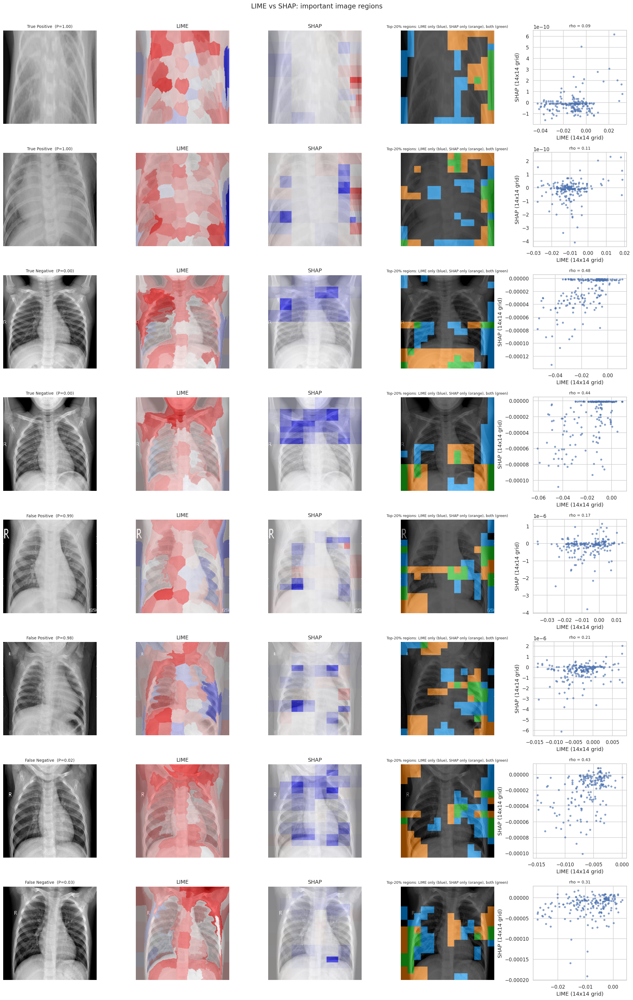

,sample,category,prob,spearman,iou_top20,pearson
0,0,True Positive,1.000,0.085,0.143,0.303
1,1,True Positive,1.000,0.106,0.250,0.217
2,2,True Negative,0.000,0.478,0.143,0.591
3,3,True Negative,0.000,0.444,0.176,0.525
4,4,False Positive,0.992,0.167,0.250,0.142
5,5,False Positive,0.979,0.205,0.143,0.229
6,6,False Negative,0.016,0.426,0.141,0.413
7,7,False Negative,0.027,0.309,0.206,0.246


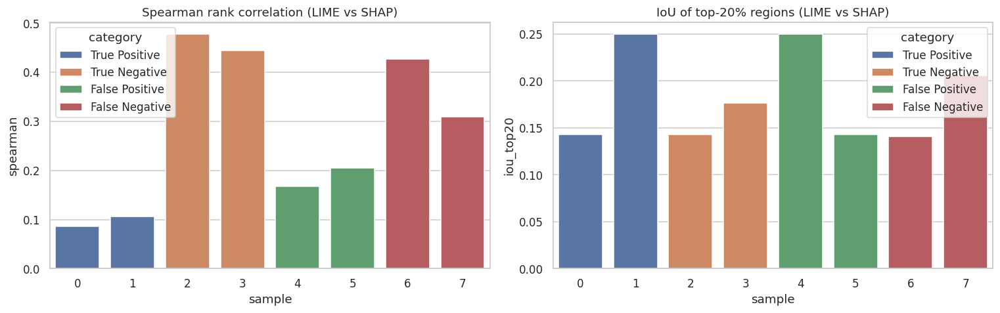

Mean Spearman = 0.278 | mean top-20% IoU = 0.181


In [34]:
GRID = 14                                           # 224 / 14 = 16 px cells
def to_grid(m, g=GRID):
    k = m.shape[0] // g
    return m.reshape(g, k, g, k).mean((1, 3))

def topk_mask(m, frac=0.20):
    return m >= np.quantile(m, 1 - frac)

def iou(a, b):
    return float((a & b).sum() / max((a | b).sum(), 1))

rows = []
fig, axes = plt.subplots(len(XAI_SAMPLES), 5, figsize=(20, 3.9 * len(XAI_SAMPLES)))
for r, s in enumerate(XAI_SAMPLES):
    gl, gs = to_grid(s['lime_map']), to_grid(s['shap_map'])
    ml, ms_ = topk_mask(gl), topk_mask(gs)
    rho = spearmanr(gl.ravel(), gs.ravel())[0]
    rows.append(dict(sample=r, category=s['cat'], prob=round(s['p'], 3), spearman=rho, iou_top20=iou(ml, ms_),
                     pearson=np.corrcoef(gl.ravel(), gs.ravel())[0, 1]))
    ll, ls = np.abs(s['lime_map']).max() + 1e-8, np.abs(s['shap_map']).max() + 1e-12
    axes[r, 0].imshow(s['img']); axes[r, 0].set_title(f"{s['cat']}  (P={s['p']:.2f})", fontsize=9)
    axes[r, 1].imshow(s['img']); axes[r, 1].imshow(s['lime_map'], cmap='bwr_r', vmin=-ll, vmax=ll, alpha=0.55); axes[r, 1].set_title('LIME')
    axes[r, 2].imshow(s['img']); axes[r, 2].imshow(s['shap_map'], cmap='bwr', vmin=-ls, vmax=ls, alpha=0.55); axes[r, 2].set_title('SHAP')
    both = np.zeros((GRID, GRID, 3)); both[ml & ~ms_] = [0, 0.6, 1]; both[ms_ & ~ml] = [1, 0.5, 0]; both[ml & ms_] = [0.1, 0.8, 0.1]
    both_up = np.kron(both, np.ones((16, 16, 1)))
    axes[r, 3].imshow(s['img']); axes[r, 3].imshow(both_up, alpha=0.55)
    axes[r, 3].set_title('Top-20% regions: LIME only (blue), SHAP only (orange), both (green)', fontsize=8)
    axes[r, 4].scatter(gl.ravel(), gs.ravel(), s=12, alpha=0.6); axes[r, 4].set_xlabel('LIME (14x14 grid)'); axes[r, 4].set_ylabel('SHAP (14x14 grid)')
    axes[r, 4].set_title(f'rho = {rho:.2f}', fontsize=9)
    for a in axes[r, :4]: a.axis('off')
plt.suptitle('LIME vs SHAP: important image regions', fontsize=15, y=1.002)
save_show('26_lime_vs_shap_comparison', 'explanations')

agree = pd.DataFrame(rows)
display(agree.round(3))
agree.round(4).to_csv(DIRS['results'] / 'lime_shap_agreement.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=agree, x='sample', y='spearman', hue='category', dodge=False, ax=ax[0]); ax[0].set_title('Spearman rank correlation (LIME vs SHAP)'); ax[0].axhline(0, c='k', lw=0.8)
sns.barplot(data=agree, x='sample', y='iou_top20', hue='category', dodge=False, ax=ax[1]); ax[1].set_title('IoU of top-20% regions (LIME vs SHAP)')
save_show('27_agreement_metrics', 'explanations')
print(f"Mean Spearman = {agree.spearman.mean():.3f} | mean top-20% IoU = {agree.iou_top20.mean():.3f}")

Stability:   0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

... (4 outputs left out)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

spearman        iou_top20       
           mean    std      mean    std
method                                 
LIME      0.827  0.054     0.502  0.107
SHAP      0.993  0.007     0.972  0.033

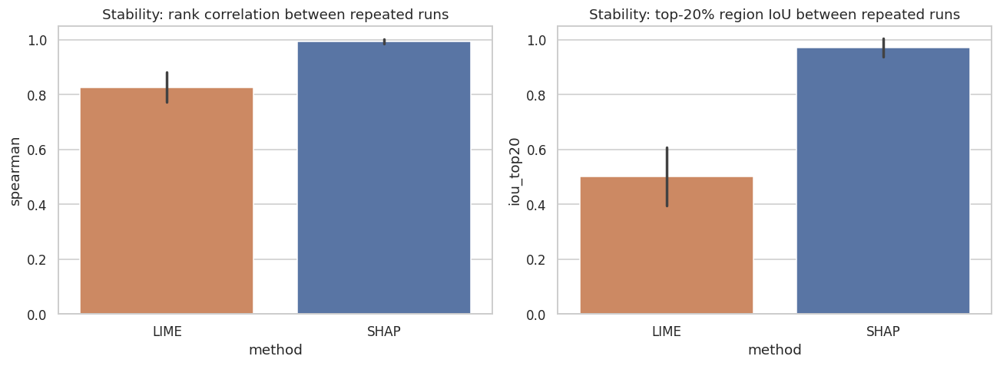

In [35]:
# ---- Explanation stability: 3 runs per image with tiny input noise (sigma=0.01) and different LIME seeds
N_STAB, N_RUNS, NOISE = min(4, len(XAI_SAMPLES)), 3, 0.01
stab_rows = []
for i in tqdm(range(N_STAB), desc='Stability'):
    img = XAI_SAMPLES[i]['img']
    L, S = [], []
    for r in range(N_RUNS):
        noisy = np.clip(img + np.random.RandomState(r).normal(0, NOISE, img.shape), 0, 1).astype(np.float32)
        L.append(to_grid(lime_weight_map(run_lime(noisy, seed=SEED + r))))
        S.append(to_grid(run_shap(noisy)))
    for name, maps in [('LIME', L), ('SHAP', S)]:
        pairs = [(a, b) for a in range(N_RUNS) for b in range(a + 1, N_RUNS)]
        stab_rows.append(dict(sample=i, method=name,
                              spearman=np.mean([spearmanr(maps[a].ravel(), maps[b].ravel())[0] for a, b in pairs]),
                              iou_top20=np.mean([iou(topk_mask(maps[a]), topk_mask(maps[b])) for a, b in pairs])))
stab = pd.DataFrame(stab_rows)
display(stab.groupby('method')[['spearman', 'iou_top20']].agg(['mean', 'std']).round(3))
stab.round(4).to_csv(DIRS['results'] / 'explanation_stability.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=stab, x='method', y='spearman', hue='method', palette=['#DD8452', '#4C72B0'], legend=False, ax=ax[0], errorbar='sd'); ax[0].set_title('Stability: rank correlation between repeated runs')
sns.barplot(data=stab, x='method', y='iou_top20', hue='method', palette=['#DD8452', '#4C72B0'], legend=False, ax=ax[1], errorbar='sd'); ax[1].set_title('Stability: top-20% region IoU between repeated runs')
for a in ax: a.set_ylim(0, 1.05)
save_show('28_explanation_stability', 'explanations')

## 12. Final prediction system
`predict_and_explain()` takes a chest X-ray, predicts NORMAL / PNEUMONIA, shows the probability and displays the LIME and SHAP explanations.
Set `USE_UPLOAD = True` to upload your own image; otherwise the cell demonstrates the system on two test images.

Demo image (ground truth: PNEUMONIA)


  0%|          | 0/1000 [00:00<?, ?it/s]

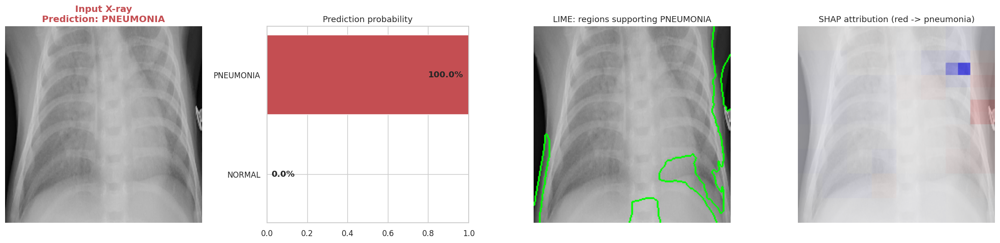

Prediction: PNEUMONIA | P(PNEUMONIA) = 1.0000 | P(NORMAL) = 0.0000
Educational prototype - not a medical device; not for clinical use.
Demo image (ground truth: NORMAL)


  0%|          | 0/1000 [00:00<?, ?it/s]

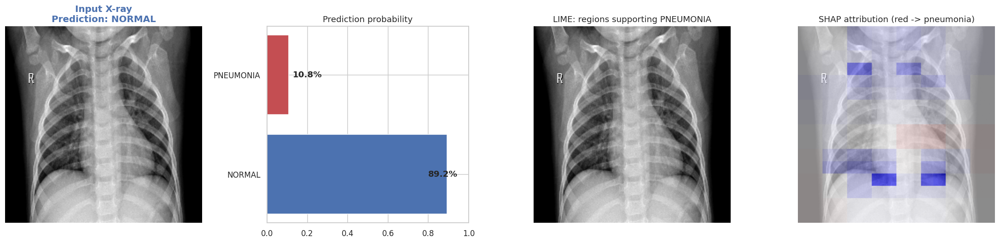

Prediction: NORMAL | P(PNEUMONIA) = 0.1078 | P(NORMAL) = 0.8922
Educational prototype - not a medical device; not for clinical use.


In [36]:
def predict_and_explain(source, lime_samples=1000, shap_evals=500, save_name=None):
    pil = source if isinstance(source, Image.Image) else Image.open(source)
    tmp = '/content/_query.png'; pil.convert('RGB').save(tmp)
    img = load_array(tmp)
    prob = float(xai_model.predict(img[None], verbose=0).ravel()[0])
    label = 'PNEUMONIA' if prob >= 0.5 else 'NORMAL'
    exp = run_lime(img, num_samples=lime_samples); lm = lime_weight_map(exp)
    sm = run_shap(img, max_evals=shap_evals)
    _, mask = exp.get_image_and_mask(1, positive_only=True, num_features=5, hide_rest=False)

    fig, ax = plt.subplots(1, 4, figsize=(20, 4.8))
    ax[0].imshow(img); ax[0].set_title(f'Input X-ray\nPrediction: {label}', color=COLORS[label], fontsize=13, fontweight='bold'); ax[0].axis('off')
    ax[1].barh(CLASS_NAMES, [1 - prob, prob], color=[COLORS[c] for c in CLASS_NAMES]); ax[1].set_xlim(0, 1)
    for i, v in enumerate([1 - prob, prob]): ax[1].text(min(v + 0.02, 0.8), i, f'{v:.1%}', va='center', fontweight='bold')
    ax[1].set_title('Prediction probability')
    ax[2].imshow(mark_boundaries(img, mask, color=(0, 1, 0), mode='thick')); ax[2].set_title('LIME: regions supporting PNEUMONIA'); ax[2].axis('off')
    lim = np.abs(sm).max() + 1e-12
    ax[3].imshow(img); ax[3].imshow(sm, cmap='bwr', vmin=-lim, vmax=lim, alpha=0.55); ax[3].set_title('SHAP attribution (red -> pneumonia)'); ax[3].axis('off')
    if save_name:
        plt.tight_layout(); plt.savefig(DIRS['explanations'] / f'{save_name}.png', bbox_inches='tight')
    plt.show()
    print(f'Prediction: {label} | P(PNEUMONIA) = {prob:.4f} | P(NORMAL) = {1 - prob:.4f}')
    print('Educational prototype - not a medical device; not for clinical use.')
    return label, prob

USE_UPLOAD = False
if USE_UPLOAD:
    from google.colab import files
    up = files.upload()
    for fn in up:
        predict_and_explain(fn, save_name='29_prediction_uploaded')
else:
    for k, lab in enumerate(['PNEUMONIA', 'NORMAL']):
        r = test_df[test_df.label == lab].sample(1, random_state=11).iloc[0]
        print(f'Demo image (ground truth: {lab})')
        predict_and_explain(r.path, save_name=f'29_prediction_demo_{lab.lower()}')

## 13. Model deployment: Streamlit web application
The next cell writes `app.py` (upload X-ray -> prediction, probability, LIME, SHAP). The following cell launches it and exposes a public URL through localtunnel.

In [37]:
%%writefile app.py
import os
import numpy as np
import streamlit as st
from PIL import Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import tensorflow as tf
from lime import lime_image
from lime.wrappers.scikit_image import SegmentationAlgorithm
from skimage.segmentation import mark_boundaries
import shap

IMG = 224
CLASS_NAMES = ['NORMAL', 'PNEUMONIA']
COLORS = {'NORMAL': '#4C72B0', 'PNEUMONIA': '#C44E52'}
MODEL_PATH = os.environ.get('MODEL_PATH', '/content/outputs/models/best_model.keras')

st.set_page_config(page_title='Pneumonia XAI', page_icon=':lungs:', layout='wide')

@st.cache_resource(show_spinner='Loading model...')
def load_model():
    return tf.keras.models.load_model(MODEL_PATH, compile=False)

model = load_model()

def preprocess(pil_img):
    img = pil_img.convert('RGB').resize((IMG, IMG), Image.BILINEAR)
    return np.asarray(img, dtype=np.float32) / 255.0

def predict_proba(x):
    p = model.predict(np.asarray(x, dtype=np.float32), batch_size=32, verbose=0).ravel()
    return np.stack([1 - p, p], axis=1)

def lime_explain(img, n_samples):
    seg = SegmentationAlgorithm('slic', n_segments=60, compactness=10, sigma=1, start_label=1)
    exp = lime_image.LimeImageExplainer(random_state=42).explain_instance(
        img.astype('double'), predict_proba, labels=(1,), top_labels=None, hide_color=0,
        num_samples=n_samples, batch_size=64, segmentation_fn=seg, random_seed=42, progress_bar=False)
    wmap = np.zeros(exp.segments.shape, np.float32)
    for sid, w in exp.local_exp[1]:
        wmap[exp.segments == sid] = w
    _, mask = exp.get_image_and_mask(1, positive_only=True, num_features=5, hide_rest=False)
    return wmap, mask

def shap_explain(img, max_evals):
    masker = shap.maskers.Image('blur(64,64)', (IMG, IMG, 3))
    explainer = shap.Explainer(lambda x: predict_proba(np.asarray(x) / 255.0), masker, output_names=CLASS_NAMES)
    sv = explainer((img * 255.0)[None].astype(np.float32), max_evals=max_evals, batch_size=50)
    v = np.asarray(sv.values)[0]
    if v.ndim == 4:
        v = v[..., -1]
    return v.sum(-1)

st.title('Explainable Pneumonia Detection from Chest X-Rays')
st.caption('Custom CNN / DenseNet121 with LIME and SHAP explanations. Educational prototype - not a medical device.')

with st.sidebar:
    st.header('Settings')
    lime_n = st.slider('LIME perturbation samples', 300, 2000, 800, 100)
    shap_n = st.slider('SHAP max evaluations', 200, 1000, 400, 100)
    show_lime = st.checkbox('Show LIME', True)
    show_shap = st.checkbox('Show SHAP', True)

file = st.file_uploader('Upload a chest X-ray image', type=['jpg', 'jpeg', 'png'])
if file is not None:
    pil = Image.open(file)
    img = preprocess(pil)
    prob = float(model.predict(img[None], verbose=0).ravel()[0])
    label = 'PNEUMONIA' if prob >= 0.5 else 'NORMAL'

    c1, c2 = st.columns([1, 1])
    with c1:
        st.image(pil, caption='Uploaded X-ray', use_container_width=True)
    with c2:
        st.subheader('Prediction')
        if label == 'PNEUMONIA':
            st.error(f'PNEUMONIA detected  -  probability {prob:.1%}')
        else:
            st.success(f'NORMAL  -  probability of pneumonia {prob:.1%}')
        st.progress(prob, text=f'P(PNEUMONIA) = {prob:.3f}')
        st.progress(1 - prob, text=f'P(NORMAL) = {1 - prob:.3f}')
        fig, ax = plt.subplots(figsize=(4, 1.6))
        ax.barh(CLASS_NAMES, [1 - prob, prob], color=[COLORS[c] for c in CLASS_NAMES]); ax.set_xlim(0, 1)
        st.pyplot(fig)

    tabs = st.tabs(['LIME', 'SHAP', 'Side by side'])
    lw = sm = None
    if show_lime:
        with st.spinner('Running LIME...'):
            lw, mask = lime_explain(img, lime_n)
        with tabs[0]:
            fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
            ax[0].imshow(img); ax[0].set_title('Input')
            ax[1].imshow(mark_boundaries(img, mask, color=(0, 1, 0), mode='thick')); ax[1].set_title('Top regions supporting PNEUMONIA')
            lim = np.abs(lw).max() + 1e-8
            ax[2].imshow(img); ax[2].imshow(lw, cmap='RdYlGn_r', vmin=-lim, vmax=lim, alpha=0.6); ax[2].set_title('LIME weights')
            for a in ax: a.axis('off')
            st.pyplot(fig)
    if show_shap:
        with st.spinner('Running SHAP...'):
            sm = shap_explain(img, shap_n)
        with tabs[1]:
            lim = np.abs(sm).max() + 1e-12
            fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
            ax[0].imshow(img); ax[0].set_title('Input')
            im = ax[1].imshow(sm, cmap='bwr', vmin=-lim, vmax=lim); ax[1].set_title('SHAP attribution'); plt.colorbar(im, ax=ax[1], fraction=0.046)
            ax[2].imshow(img); ax[2].imshow(sm, cmap='bwr', vmin=-lim, vmax=lim, alpha=0.55); ax[2].set_title('Overlay (red = pneumonia)')
            for a in ax: a.axis('off')
            st.pyplot(fig)
    if lw is not None and sm is not None:
        with tabs[2]:
            fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
            l1, l2 = np.abs(lw).max() + 1e-8, np.abs(sm).max() + 1e-12
            ax[0].imshow(img); ax[0].imshow(lw, cmap='bwr_r', vmin=-l1, vmax=l1, alpha=0.55); ax[0].set_title('LIME')
            ax[1].imshow(img); ax[1].imshow(sm, cmap='bwr', vmin=-l2, vmax=l2, alpha=0.55); ax[1].set_title('SHAP')
            for a in ax: a.axis('off')
            st.pyplot(fig)
else:
    st.info('Upload a chest X-ray (JPEG/PNG) to get a prediction with explanations.')

Writing app.py


In [38]:
LAUNCH_APP = True      # set False to skip launching the web app
shutil.copy('app.py', DIRS['app'] / 'app.py')
open(DIRS['app'] / 'requirements.txt', 'w').write('streamlit\ntensorflow\nlime\nshap\nscikit-image\nmatplotlib\nnumpy\nPillow\n')

if LAUNCH_APP:
    import subprocess, select, urllib.request
    os.system('pip install -q streamlit')
    os.environ['MODEL_PATH'] = str(DIRS['models'] / 'best_model.keras')
    subprocess.Popen('streamlit run app.py --server.port 8501 --server.headless true > streamlit.log 2>&1', shell=True)
    time.sleep(8)
    lt = subprocess.Popen(['npx', '--yes', 'localtunnel', '--port', '8501'], stdout=subprocess.PIPE, text=True)
    url, t0 = None, time.time()
    while time.time() - t0 < 60 and url is None:
        if select.select([lt.stdout], [], [], 2)[0]:
            line = lt.stdout.readline()
            if 'https://' in line:
                url = line.split('is:')[-1].strip()
    ip = urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode().strip()
    print('Streamlit app URL   :', url)
    print('Tunnel password (IP):', ip, ' <- paste into the localtunnel page the first time you open the URL')
    print('(The app stays up while this Colab session is alive. Logs: streamlit.log)')
else:
    print('App written to', DIRS['app'] / 'app.py', '- run with:  streamlit run app.py')

Streamlit app URL   : https://tidy-schools-cut.loca.lt
Tunnel password (IP): 34.126.87.95  <- paste into the localtunnel page the first time you open the URL
(The app stays up while this Colab session is alive. Logs: streamlit.log)


## Save everything to Google Drive
Creates a project folder in your Drive and copies all plots, graphs, confusion matrices, XAI figures, result tables, model weights and trained models.

In [44]:
import os
import json
import shutil
import time
from pathlib import Path
from google.colab import files

# Save project summary
summary = dict(
    best_model=best_name,
    seed=SEED,
    split_images={k: int(v) for k, v in summary.total.items()},
    test_metrics=json.loads(test_tbl.to_json(orient='index')),
    youden_threshold_val=youden_thr,
    lime_shap_mean_spearman=float(agree.spearman.mean()),
    lime_shap_mean_iou_top20=float(agree.iou_top20.mean()),
    training_minutes={k: round(v / 60, 1) for k, v in train_time.items()}
)

json.dump(
    summary,
    open(DIRS['results'] / 'project_summary.json', 'w'),
    indent=2
)

# Create a project folder in Colab runtime
stamp = time.strftime('%Y%m%d_%H%M')
PROJECT_DIR = Path('/content') / f'Pneumonia_XAI_MiniProject_{stamp}'
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

# Copy all project directories
for sub in ['plots', 'explanations', 'results', 'models', 'weights', 'app']:
    shutil.copytree(
        DIRS[sub],
        PROJECT_DIR / sub,
        dirs_exist_ok=True
    )

# Copy app.py if available
if Path('app.py').exists():
    shutil.copy('app.py', PROJECT_DIR / 'app' / 'app.py')

# Create ZIP archive
ZIP_PATH = shutil.make_archive(
    str(PROJECT_DIR),
    'zip',
    root_dir='/content',
    base_dir=PROJECT_DIR.name
)

print("Project packaged successfully!")
print("ZIP:", ZIP_PATH)
print("\nProject contents:")

for sub in ['plots', 'explanations', 'results', 'models', 'weights', 'app']:
    files_ = sorted(p.name for p in (PROJECT_DIR / sub).glob('*'))
    print(f'\n{sub}/ ({len(files_)} files)')
    for f in files_:
        print('   ', f)

# Download directly to your computer
files.download(ZIP_PATH)

Project packaged successfully!
ZIP: /content/Pneumonia_XAI_MiniProject_20261105_1527.zip

Project contents:

plots/ (21 files)
    01_class_distribution.png
    02_subtype_distribution.png
    03_sample_images.png
    04_image_size_statistics.png
    05_pixel_statistics.png
    06_cleaning_summary.png
    07_original_split_leakage_audit.png
    08_split_distribution.png
    09_preprocessing_example.png
    10_augmentation_examples.png
    11_training_curves_custom_cnn.png
    11_training_curves_densenet121.png
    12_validation_comparison.png
    13_confusion_matrices_test.png
    14_confusion_matrices_validation.png
    15_roc_pr_calibration.png
    16_probability_distributions.png
    17_metric_comparison.png
    18_generalisation_gap.png
    19_threshold_analysis.png
    20_misclassified_examples.png

explanations/ (10 files)
    21_xai_selected_samples.png
    22_lime_explanations.png
    23_lime_superpixel_weights.png
    24_shap_explanations.png
    25_shap_mean_attribution_by_cl

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>